In [1]:
import json
import os
import time
import warnings

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

CONFIG = dict(
    OUTPUT_DIR         = "wyniki_klasteryzacji",                               
    SEED               = 42,
)
np.random.seed(CONFIG["SEED"])

EMB_DIR = "wyniki_embeddingow"
CSV_PATH = "../dane/fra_cleaned_final.csv"
os.makedirs(CONFIG["OUTPUT_DIR"], exist_ok=True)
print("folder z osadzeniami:", EMB_DIR, "| plik CSV:", CSV_PATH)

# --- wczytanie trzech plikow ---
Z = np.load(os.path.join(EMB_DIR, "Z_final.npy"))
index = pd.read_csv(os.path.join(EMB_DIR, "perfume_index.csv"), sep=";", encoding="utf-8-sig")
df = pd.read_csv(CSV_PATH, sep=";", encoding="utf-8-sig")
meta = json.load(open(os.path.join(EMB_DIR, "embeddings_meta.json"), encoding="utf-8"))
N = len(df)

# --- kontrole zgodnosci ---
normy = np.linalg.norm(Z, axis=1)
kontrole = {
    "ksztalt Z (perfumy, wymiary)":                      Z.shape,
    "typ danych Z":                                      str(Z.dtype),
    "liczba wierszy: Z == indeks == CSV":                (Z.shape[0] == len(index) == N),
    "url w indeksie zgodne z CSV (ta sama kolejnosc)":   bool((index.url.values == df.url.values).all()),
    "perfume_id unikalne":                               bool(index.perfume_id.is_unique),
    "wektory bez NaN/inf":                               bool(np.isfinite(Z).all()),
    "dlugosc wektorow (min, max)":                       (round(float(normy.min()), 6), round(float(normy.max()), 6)),
}
for k, v in kontrole.items():
    print(f"{k:52s} {v}")

print("\nparametry z embeddings_meta.json:")
for k in ["HYBRID_W_A", "DIM", "A_ALPHA_ACCORD", "B_ACCORD_GAIN", "B_TOP1_WEIGHT", "B_PPMI_SHIFT", "MIN_DF_NOTE", "SEED"]:
    print(f"  {k:16s} {meta['config'].get(k)}")
print("kolumny:", meta.get("kolumny 0-255"), "|", meta.get("kolumny 256-511"))

folder z osadzeniami: wyniki_embeddingow | plik CSV: ../dane/fra_cleaned_final.csv
ksztalt Z (perfumy, wymiary)                         (24046, 512)
typ danych Z                                         float32
liczba wierszy: Z == indeks == CSV                   True
url w indeksie zgodne z CSV (ta sama kolejnosc)      True
perfume_id unikalne                                  True
wektory bez NaN/inf                                  True
dlugosc wektorow (min, max)                          (1.0, 1.0)

parametry z embeddings_meta.json:
  HYBRID_W_A       0.3
  DIM              256
  A_ALPHA_ACCORD   0.4
  B_ACCORD_GAIN    1.5
  B_TOP1_WEIGHT    0.75
  B_PPMI_SHIFT     0.69
  MIN_DF_NOTE      3
  SEED             42
kolumny: metoda A | metoda B*


In [2]:
from scipy.stats import skew

brand_id = pd.factorize(df.Brand)[0]
rng = np.random.default_rng(CONFIG["SEED"])

# --- 1) losowe pary perfum: jak wyglada "brak podobienstwa" ---
a, b = rng.integers(0, N, 300_000), rng.integers(0, N, 300_000)
ok = a != b
cos_los = np.einsum("ij,ij->i", Z[a[ok]], Z[b[ok]])

# --- 2) najblizsi sasiedzi kazdych perfum (porcjami, zeby nie zajac pamieci) ---
top10_all = np.zeros((N, 10), dtype=np.int64)     # 10 najblizszych (wszystkie marki)
nn_all = np.zeros(N, dtype=np.float32)            # cosinus do najblizszego sasiada
nn_cross = np.zeros(N, dtype=np.float32)          # cosinus do najblizszego sasiada Z INNEJ MARKI
sim_10 = np.zeros(N, dtype=np.float32)            # cosinus do 10. sasiada
nn_same_brand = np.zeros(N, dtype=bool)           # czy najblizszy sasiad jest z tej samej marki

t0, chunk = time.time(), 1000
for s in range(0, N, chunk):
    idx = np.arange(s, min(s + chunk, N))
    sim = Z[idx] @ Z.T
    sim[np.arange(len(idx)), idx] = -9                                   # perfumy nie sa wlasnym sasiadem
    part = np.argpartition(-sim, 10, axis=1)[:, :10]
    vals = np.take_along_axis(sim, part, axis=1)
    order = np.argsort(-vals, axis=1, kind="stable")
    top10_all[idx] = np.take_along_axis(part, order, axis=1)
    sorted_vals = np.take_along_axis(vals, order, axis=1)
    nn_all[idx], sim_10[idx] = sorted_vals[:, 0], sorted_vals[:, 9]
    nn_same_brand[idx] = brand_id[top10_all[idx, 0]] == brand_id[idx]
    sim[brand_id[idx][:, None] == brand_id[None, :]] = -9                # wyklucz ta sama marke
    nn_cross[idx] = sim.max(axis=1)
print(f"czas liczenia sasiadow: {time.time() - t0:.0f} s")

# --- 3) tabela percentyli ---
pct = [1, 5, 25, 50, 75, 95, 99]
tab = pd.DataFrame({
    "losowe pary":                          np.percentile(cos_los, pct),
    "najblizszy sasiad (wszystkie marki)":  np.percentile(nn_all, pct),
    "najblizszy sasiad (inna marka)":       np.percentile(nn_cross, pct),
    "10. najblizszy sasiad":                np.percentile(sim_10, pct),
}, index=[f"p{p}" for p in pct]).round(3)
print("\ncosinus (percentyle rozkladu):")
display(tab)
print(f"losowe pary: srednia {cos_los.mean():.3f}, odchylenie {cos_los.std():.3f}")

# --- 4) prawie identyczne perfumy (wersje meska/damska, flankery) ---
print("\nperfumy z 'blizniakiem' (cos najblizszego sasiada >= prog):")
for prog in [0.999, 0.99, 0.95, 0.90]:
    m = nn_all >= prog
    print(f"  >= {prog}: {int(m.sum()):5d} perfum ({m.mean():.1%}), z czego bliznik z tej samej marki: {nn_same_brand[m].mean():.1%}")

# --- 5) hubness: ile razy kazde perfumy trafiaja do cudzych list top-10 ---
nk = np.bincount(top10_all.ravel(), minlength=N)
udzial_top1 = np.sort(nk)[::-1][:N // 100].sum() / nk.sum()
print(f"\nhubness (top-10): skosnosc {skew(nk):.2f}, perfumy nie wystepujace w zadnej cudzej liscie {np.mean(nk == 0):.1%}, "
      f"maksimum wystapien {nk.max()}, 1% najczesciej wybieranych perfum zajmuje {udzial_top1:.1%} miejsc na listach")

czas liczenia sasiadow: 3 s

cosinus (percentyle rozkladu):


,losowe pary,najblizszy sasiad (wszystkie marki),najblizszy sasiad (inna marka),10. najblizszy sasiad
p1,-0.423,0.595,0.592,0.519
p5,-0.337,0.668,0.662,0.588
p25,-0.156,0.755,0.749,0.681
p50,0.015,0.808,0.800,0.738
p75,0.224,0.854,0.842,0.783
p95,0.524,0.941,0.902,0.834
p99,0.666,0.987,0.962,0.862


losowe pary: srednia 0.045, odchylenie 0.262

perfumy z 'blizniakiem' (cos najblizszego sasiada >= prog):
  >= 0.999:    79 perfum (0.3%), z czego bliznik z tej samej marki: 84.8%
  >= 0.99:   210 perfum (0.9%), z czego bliznik z tej samej marki: 78.1%
  >= 0.95:  1027 perfum (4.3%), z czego bliznik z tej samej marki: 66.0%
  >= 0.9:  2463 perfum (10.2%), z czego bliznik z tej samej marki: 54.8%

hubness (top-10): skosnosc 2.24, perfumy nie wystepujace w zadnej cudzej liscie 5.9%, maksimum wystapien 109, 1% najczesciej wybieranych perfum zajmuje 5.9% miejsc na listach


In [3]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize

# --- 1) PCA: ile "osi" niesie wiekszosc zroznicowania perfum ---
t0 = time.time()
pca = PCA(n_components=128, random_state=CONFIG["SEED"]).fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_)
print(f"PCA policzone w {time.time() - t0:.0f} s")
print("udzial wariancji wyjasniony przez pierwsze d osi:")
for d in [2, 5, 10, 16, 32, 64, 128]:
    print(f"  d = {d:3d}: {cum[d - 1]:.1%}")

# --- 2) reprezentacje zredukowane: pierwsze d osi PCA, wektory znow skrocone do dlugosci 1 (cosinus) ---
Z_pca_full = pca.transform(Z)                       # (N, 128), osie uporzadkowane od najwazniejszej
DIMS = [8, 16, 32, 64, 128]
Z_red = {d: normalize(Z_pca_full[:, :d]).astype(np.float32) for d in DIMS}

# --- 3) czy redukcja zachowuje sasiedztwo? top-10 w pelnej przestrzeni vs w zredukowanej ---
q = np.sort(np.random.default_rng(CONFIG["SEED"]).choice(N, 2000, replace=False))   # 2000 losowych perfum
wiersze = []
for d in DIMS:
    sim = Z_red[d][q] @ Z_red[d].T
    sim[np.arange(len(q)), q] = -9
    top_d = np.argpartition(-sim, 10, axis=1)[:, :10]
    zgodnosc = np.mean([len(set(top_d[i]) & set(top10_all[qi])) / 10 for i, qi in enumerate(q)])
    wiersze.append({"wymiary d": d, "wariancja": f"{cum[d - 1]:.1%}", "zgodnosc top-10 z pelna przestrzenia": round(zgodnosc, 3)})
print("\nzachowanie sasiedztwa po redukcji (1.0 = identyczne listy top-10):")
display(pd.DataFrame(wiersze))

PCA policzone w 0 s
udzial wariancji wyjasniony przez pierwsze d osi:
  d =   2: 33.1%
  d =   5: 49.0%
  d =  10: 61.4%
  d =  16: 68.6%
  d =  32: 77.1%
  d =  64: 84.8%
  d = 128: 91.7%

zachowanie sasiedztwa po redukcji (1.0 = identyczne listy top-10):


,wymiary d,wariancja,zgodnosc top-10 z pelna przestrzenia
0,8,57.6%,0.176
1,16,68.6%,0.345
2,32,77.1%,0.505
3,64,84.8%,0.619
4,128,91.7%,0.736


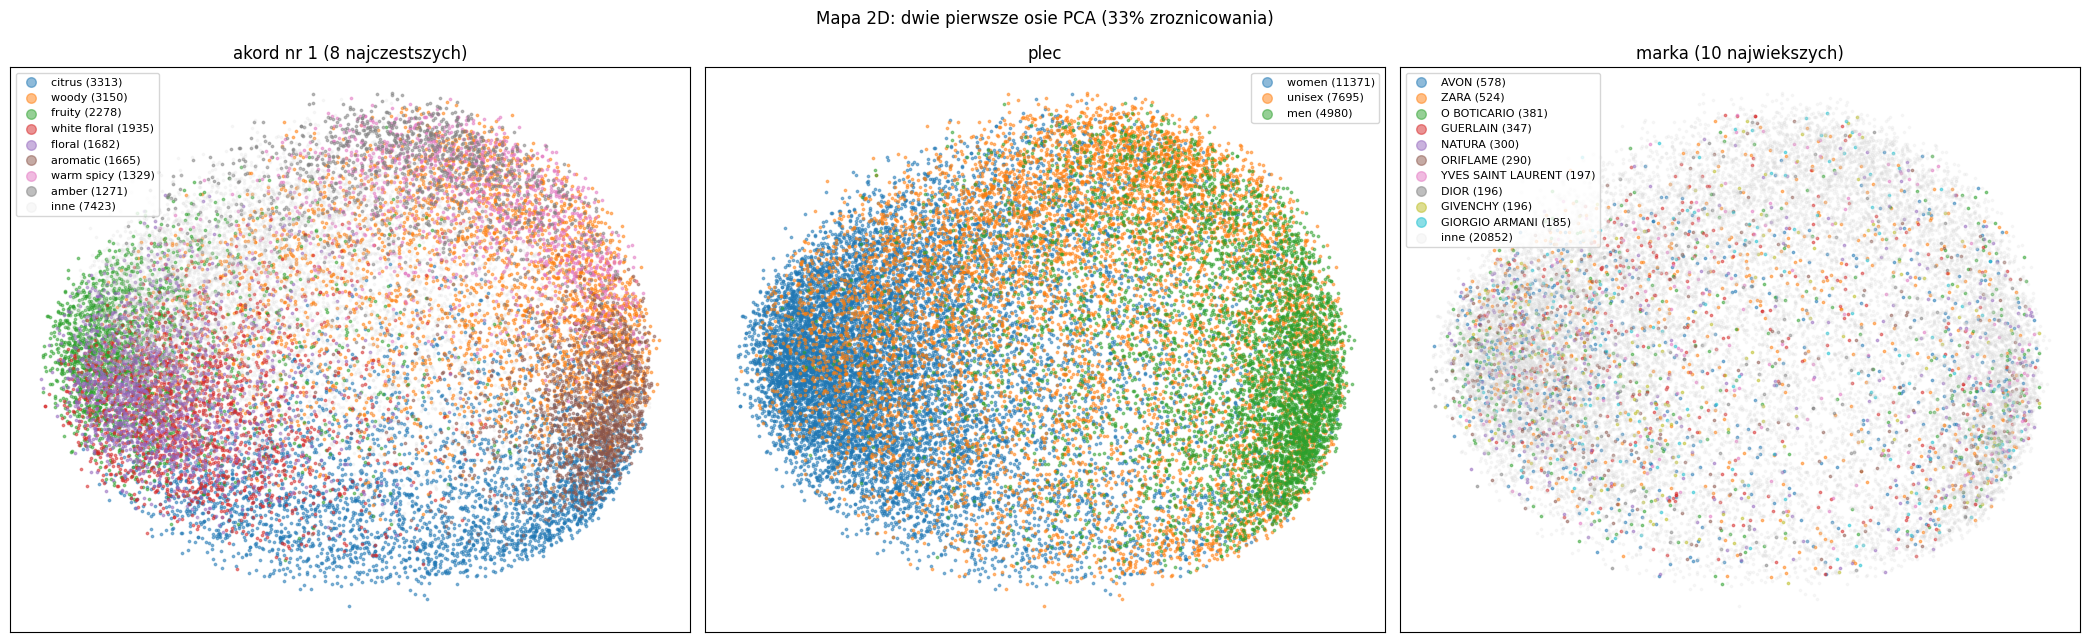

oś PCA 1:
   wartosci WIEKSZE przy akordach: aromatic (+0.69), fresh spicy (+0.57), woody (+0.44), warm spicy (+0.37), citrus (+0.22), lavender (+0.20)
   wartosci MNIEJSZE przy akordach: fruity (-0.53), floral (-0.46), sweet (-0.45), white floral (-0.35), powdery (-0.27), fresh (-0.26)
oś PCA 2:
   wartosci WIEKSZE przy akordach: amber (+0.50), warm spicy (+0.48), vanilla (+0.33), balsamic (+0.23), oud (+0.22), powdery (+0.22)
   wartosci MNIEJSZE przy akordach: citrus (-0.66), green (-0.32), aromatic (-0.29), white floral (-0.29), fresh (-0.25), fresh spicy (-0.21)

srednie polozenie wg plci (os 1, os 2):


os 1          os 2       
         mean    std   mean    std
men     0.494  0.270 -0.043  0.302
unisex  0.130  0.391  0.095  0.357
women  -0.304  0.325 -0.045  0.285

In [4]:
import matplotlib.pyplot as plt

# --- 1) akordy perfum: do kolorowania map i do interpretacji osi (wagi rangowe jak w embeddings) ---
acc_cols = [f"mainaccord{i}" for i in range(1, 6)]
accords_l = df[acc_cols].apply(lambda r: [str(x).strip().lower() for x in r if isinstance(x, str) and x.strip()], axis=1)
top1 = accords_l.map(lambda l: l[0] if l else "brak")                    # akord nr 1 kazdych perfum
RANKW = [1.0, 0.75, 0.56, 0.42, 0.32]
acc_names = sorted({a for l in accords_l for a in l})
acc_idx = {a: i for i, a in enumerate(acc_names)}
A = np.zeros((N, len(acc_names)), dtype=np.float32)                       # N x 84, waga akordu w perfumach
for i, l in enumerate(accords_l):
    for r, a in enumerate(l[:5]):
        A[i, acc_idx[a]] = RANKW[r]

# --- 2) funkcja rysujaca mape 2D z trzema kolorowaniami (uzyjemy jej tez dla UMAP) ---
def kategorie_top(serie, n_top):
    """n_top najczestszych wartosci zostaje, reszta -> 'inne'"""
    najczestsze = serie.value_counts().index[:n_top]
    return serie.where(serie.isin(najczestsze), "inne")

def rysuj_mape(xy, tytul, plik=None):
    panele = [("akord nr 1 (8 najczestszych)", kategorie_top(top1, 8)),
              ("plec", df.Gender),
              ("marka (10 najwiekszych)", kategorie_top(df.Brand, 10))]
    fig, osie = plt.subplots(1, 3, figsize=(21, 6.5))
    for ax, (nazwa, kat) in zip(osie, panele):
        wartosci = [w for w in kat.value_counts().index if w != "inne"] + (["inne"] if (kat == "inne").any() else [])
        kolory = plt.cm.tab10(np.arange(len(wartosci)) % 10)
        for w, kol in zip(wartosci, kolory):
            m = (kat == w).values
            ax.scatter(xy[m, 0], xy[m, 1], s=3, alpha=0.5 if w != "inne" else 0.15,
                       color="lightgray" if w == "inne" else kol, label=f"{w} ({m.sum()})")
        ax.set_title(nazwa); ax.legend(markerscale=4, fontsize=8, loc="best"); ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(tytul); fig.tight_layout()
    if plik:
        fig.savefig(os.path.join(CONFIG["OUTPUT_DIR"], plik), dpi=110)
    plt.show()

xy_pca = Z_pca_full[:, :2]
rysuj_mape(xy_pca, "Mapa 2D: dwie pierwsze osie PCA (33% zroznicowania)", "mapa_pca.png")

# --- 3) co oznaczaja dwie pierwsze osie? korelacja polozenia z obecnoscia akordow ---
def korelacje_z_osia(wynik_osi, k=6):
    Ac = A - A.mean(0)
    sc = wynik_osi - wynik_osi.mean()
    korelacja = (Ac.T @ sc) / (np.linalg.norm(Ac, axis=0) * np.linalg.norm(sc) + 1e-12)
    kolej = np.argsort(korelacja)
    plus = ", ".join(f"{acc_names[j]} ({korelacja[j]:+.2f})" for j in kolej[::-1][:k])
    minus = ", ".join(f"{acc_names[j]} ({korelacja[j]:+.2f})" for j in kolej[:k])
    return plus, minus

for ktora in [0, 1]:
    plus, minus = korelacje_z_osia(Z_pca_full[:, ktora])
    print(f"oś PCA {ktora + 1}:\n   wartosci WIEKSZE przy akordach: {plus}\n   wartosci MNIEJSZE przy akordach: {minus}")

print("\nsrednie polozenie wg plci (os 1, os 2):")
display(pd.DataFrame(Z_pca_full[:, :2], columns=["os 1", "os 2"]).groupby(df.Gender.values).agg(["mean", "std"]).round(3))

In [ ]:
try:
    import umap
except ImportError:
    raise ImportError("Zainstaluj pakiet poleceniem: pip install umap-learn")

# --- 1) UMAP z pelnych wektorow (cosinus) ---
t0 = time.time()
reducer = umap.UMAP(n_neighbors=30, min_dist=0.1, n_components=2, metric="cosine",
                    random_state=CONFIG["SEED"])
xy_umap = reducer.fit_transform(Z)
print(f"UMAP policzone w {time.time() - t0:.0f} s")
np.save(os.path.join(CONFIG["OUTPUT_DIR"], "xy_umap.npy"), xy_umap)

rysuj_mape(xy_umap, "Mapa 2D: UMAP (cosinus, n_neighbors=30, min_dist=0.1)", "mapa_umap.png")

# --- 2) jakosc map: ilu z 10 najblizszych sasiadow na mapie jest tez w top-10 w pelnej przestrzeni ---
def zgodnosc_2d(xy, q, k=10):
    xy = xy.astype(np.float32); kw = (xy ** 2).sum(1)
    wyniki = []
    for s in range(0, len(q), 500):
        qi = q[s:s + 500]
        d2 = kw[qi][:, None] + kw[None, :] - 2 * xy[qi] @ xy.T            # kwadraty odleglosci euklidesowych
        d2[np.arange(len(qi)), qi] = np.inf
        top2d = np.argpartition(d2, k, axis=1)[:, :k]
        wyniki += [len(set(top2d[i]) & set(top10_all[x])) / k for i, x in enumerate(qi)]
    return float(np.mean(wyniki))

q2 = np.sort(np.random.default_rng(CONFIG["SEED"]).choice(N, 2000, replace=False))
print(f"zgodnosc top-10 z pelna przestrzenia: PCA 2D = {zgodnosc_2d(xy_pca, q2):.3f}, UMAP 2D = {zgodnosc_2d(xy_umap, q2):.3f}")

C:\Users\Adam\AppData\Roaming\Python\Python312\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP policzone w 36 s


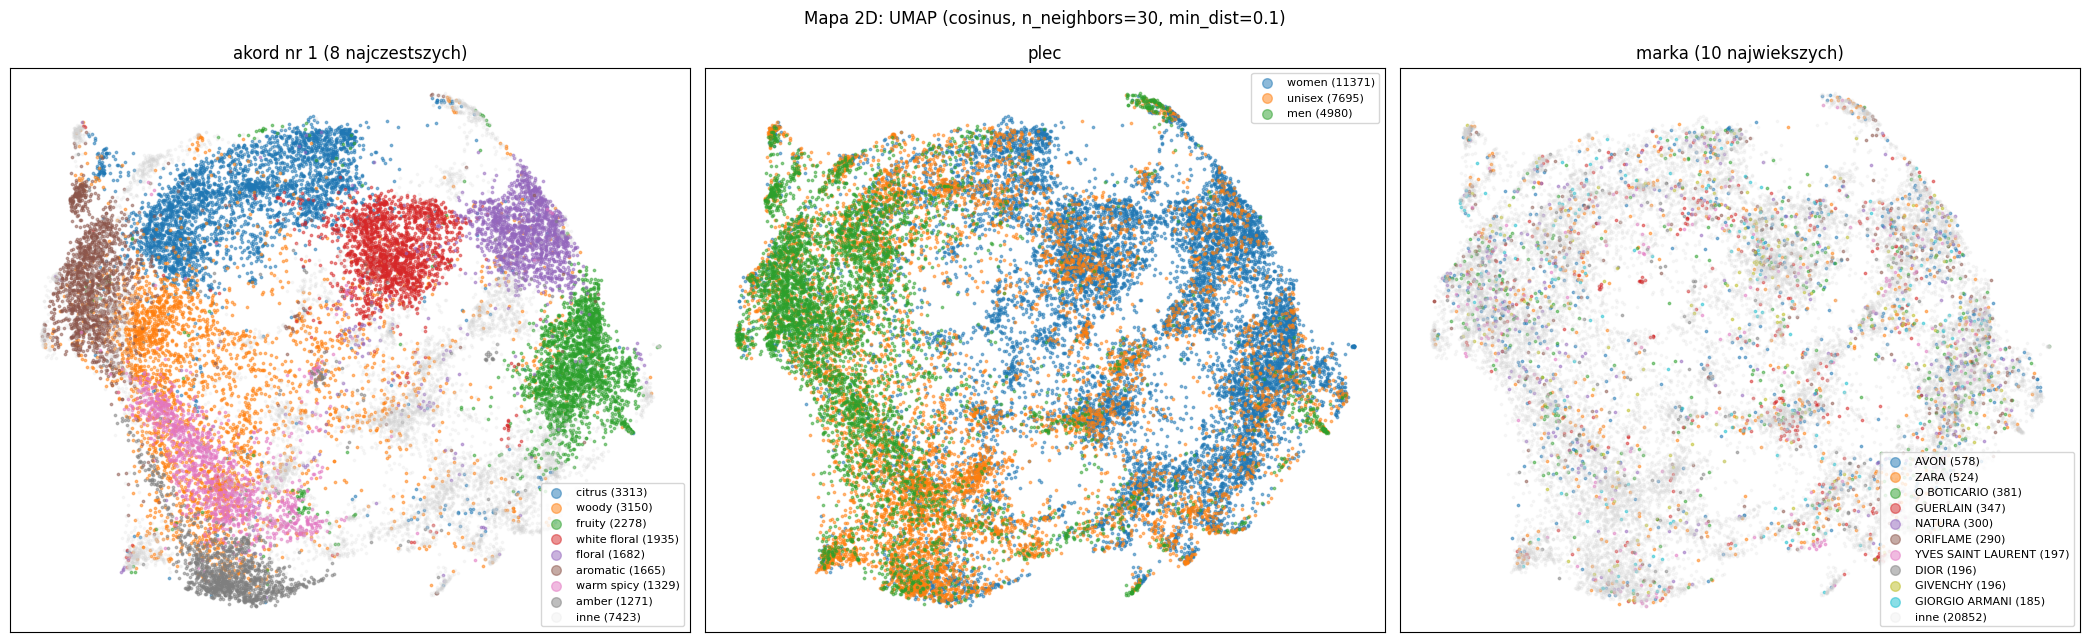

zgodnosc top-10 z pelna przestrzenia: PCA 2D = 0.012, UMAP 2D = 0.091


In [8]:
import sys
sys.modules["tensorflow"] = None        
import umap                             
# --- 1) UMAP z pelnych wektorow (cosinus) ---
t0 = time.time()
reducer = umap.UMAP(n_neighbors=30, min_dist=0.1, n_components=2, metric="cosine",
                    random_state=CONFIG["SEED"])
xy_umap = reducer.fit_transform(Z)
print(f"UMAP policzone w {time.time() - t0:.0f} s")
np.save(os.path.join(CONFIG["OUTPUT_DIR"], "xy_umap.npy"), xy_umap)

rysuj_mape(xy_umap, "Mapa 2D: UMAP (cosinus, n_neighbors=30, min_dist=0.1)", "mapa_umap.png")

# --- 2) jakosc map: ilu z 10 najblizszych sasiadow na mapie jest tez w top-10 w pelnej przestrzeni ---
def zgodnosc_2d(xy, q, k=10):
    xy = xy.astype(np.float32); kw = (xy ** 2).sum(1)
    wyniki = []
    for s in range(0, len(q), 500):
        qi = q[s:s + 500]
        d2 = kw[qi][:, None] + kw[None, :] - 2 * xy[qi] @ xy.T            # kwadraty odleglosci euklidesowych
        d2[np.arange(len(qi)), qi] = np.inf
        top2d = np.argpartition(d2, k, axis=1)[:, :k]
        wyniki += [len(set(top2d[i]) & set(top10_all[x])) / k for i, x in enumerate(qi)]
    return float(np.mean(wyniki))

q2 = np.sort(np.random.default_rng(CONFIG["SEED"]).choice(N, 2000, replace=False))
print(f"zgodnosc top-10 z pelna przestrzenia: PCA 2D = {zgodnosc_2d(xy_pca, q2):.3f}, UMAP 2D = {zgodnosc_2d(xy_umap, q2):.3f}")

  k =  8 policzone (4 s)
  k = 10 policzone (7 s)
  k = 12 policzone (11 s)
  k = 14 policzone (15 s)
  k = 16 policzone (20 s)
  k = 20 policzone (26 s)
  k = 24 policzone (33 s)
  k = 30 policzone (41 s)


,k,rozmiar min,mediana,max,max udzial,spojnosc R sr.,R min,sylwetka,Davies-Bouldin,granica <0.03,granica <0.06,stabilnosc ARI
0,8,1847,2699,4683,0.195,0.625,0.569,0.199,2.330,0.074,0.146,0.995
1,10,1765,2384,3333,0.139,0.638,0.582,0.163,2.687,0.103,0.208,0.847
2,12,1045,2016,3215,0.134,0.641,0.440,0.166,2.518,0.103,0.205,0.721
3,14,934,1738,2450,0.102,0.654,0.464,0.143,2.667,0.129,0.252,0.791
4,16,807,1420,2296,0.095,0.659,0.490,0.145,2.611,0.134,0.262,0.965
5,20,462,1138,2265,0.094,0.671,0.491,0.135,2.727,0.149,0.293,0.805
6,24,444,933,2083,0.087,0.680,0.478,0.114,2.901,0.184,0.356,0.698
7,30,195,757,1907,0.079,0.691,0.563,0.107,2.820,0.204,0.388,0.667


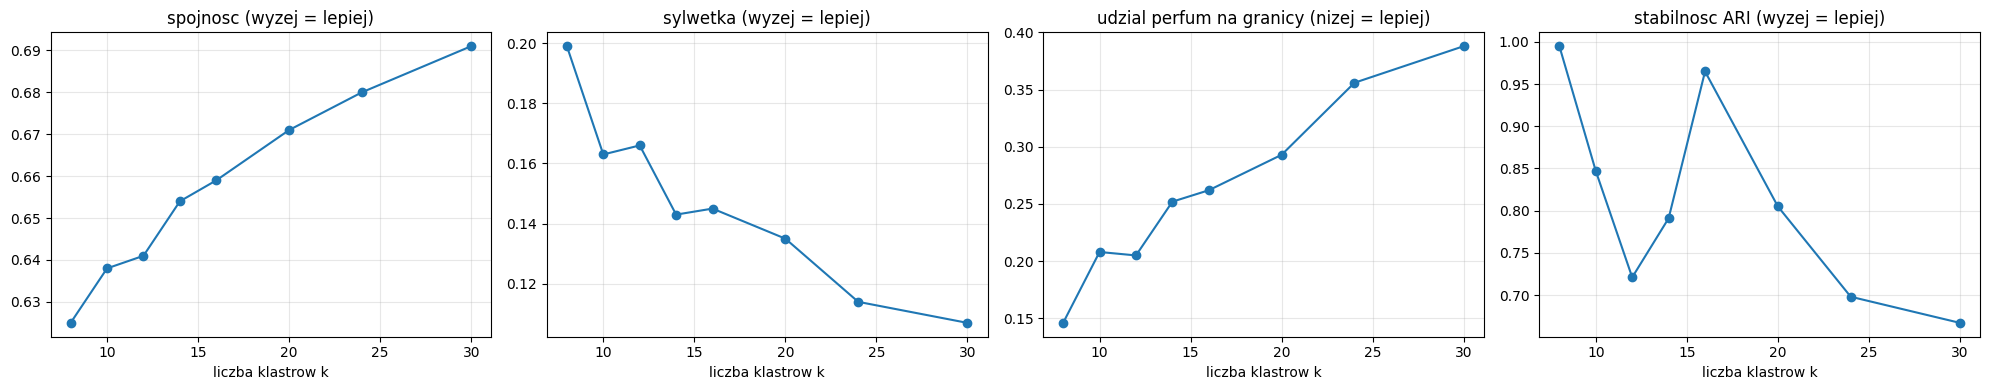

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score

K_LISTA = [8, 10, 12, 14, 16, 20, 24, 30]
SEEDY = [CONFIG["SEED"], CONFIG["SEED"] + 1, CONFIG["SEED"] + 2]          # trzy uruchomienia do oceny stabilnosci
probka_sil = np.sort(np.random.default_rng(CONFIG["SEED"]).choice(N, 5000, replace=False))

def srodki_i_margines(Z, etykiety, k):
    """Srodki klastrow (jednostkowe), spojnosc R i margines = (cos do najblizszego srodka) - (cos do drugiego)"""
    srednie = np.vstack([Z[etykiety == c].mean(0) for c in range(k)])
    R = np.linalg.norm(srednie, axis=1)                                      # dlugosc sredniego wektora jednostkowego
    C = srednie / R[:, None]
    sim = Z @ C.T
    srt = np.sort(sim, axis=1)
    return C, R, srt[:, -1] - srt[:, -2]

labels_k, centra_k, wiersze, t0 = {}, {}, [], time.time()
for k in K_LISTA:
    przebiegi = [KMeans(n_clusters=k, n_init=3, random_state=s).fit(Z).labels_ for s in SEEDY]
    lab = przebiegi[0]                                                       # glowny podzial = pierwsze ziarno
    C, R, margines = srodki_i_margines(Z, lab, k)
    rozmiary = np.bincount(lab, minlength=k)
    ari = np.mean([adjusted_rand_score(przebiegi[i], przebiegi[j]) for i in range(3) for j in range(i + 1, 3)])
    labels_k[k], centra_k[k] = lab, C
    wiersze.append({"k": k,
                    "rozmiar min": int(rozmiary.min()), "mediana": int(np.median(rozmiary)), "max": int(rozmiary.max()),
                    "max udzial": round(rozmiary.max() / N, 3),
                    "spojnosc R sr.": round(R.mean(), 3), "R min": round(R.min(), 3),
                    "sylwetka": round(silhouette_score(Z[probka_sil], lab[probka_sil], metric="cosine"), 3),
                    "Davies-Bouldin": round(davies_bouldin_score(Z, lab), 3),
                    "granica <0.03": round(float((margines < 0.03).mean()), 3),
                    "granica <0.06": round(float((margines < 0.06).mean()), 3),
                    "stabilnosc ARI": round(float(ari), 3)})
    print(f"  k = {k:2d} policzone ({time.time() - t0:.0f} s)")

skan = pd.DataFrame(wiersze)
display(skan)
skan.to_csv(os.path.join(CONFIG["OUTPUT_DIR"], "skan_k.csv"), index=False)

# --- wykresy miar w funkcji liczby klastrow ---
fig, osie = plt.subplots(1, 4, figsize=(20, 4))
for ax, (kol, tyt) in zip(osie, [("spojnosc R sr.", "spojnosc (wyzej = lepiej)"), ("sylwetka", "sylwetka (wyzej = lepiej)"),
                                 ("granica <0.06", "udzial perfum na granicy (nizej = lepiej)"), ("stabilnosc ARI", "stabilnosc ARI (wyzej = lepiej)")]):
    ax.plot(skan.k, skan[kol], "o-"); ax.set_title(tyt); ax.set_xlabel("liczba klastrow k"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["OUTPUT_DIR"], "skan_k.png"), dpi=110); plt.show()

In [10]:
from sklearn.metrics import roc_auc_score

rng7 = np.random.default_rng(CONFIG["SEED"])

def auc_centrum(lab, k, n_losowanych, powtorzen=40, n_neg=2000):
    """Dla kazdego klastra: losujemy n_losowanych czlonkow ('lubiane perfumy uzytkownika'), liczymy ich centrum
    i sprawdzamy, czy cosinus do centrum odroznia POZOSTALYCH czlonkow klastra od perfum z innych klastrow.
    Zwraca (AUC centrum, AUC najblizszego z wylosowanych), usrednione po powtorzeniach, dla kazdego klastra."""
    wyniki_c, wyniki_n = np.zeros(k), np.zeros(k)
    for c in range(k):
        czlonkowie = np.where(lab == c)[0]
        obcy = np.where(lab != c)[0]
        auc_c, auc_n = [], []
        for _ in range(powtorzen):
            pol = rng7.choice(czlonkowie, n_losowanych, replace=False)
            reszta = np.setdiff1d(czlonkowie, pol)
            neg = rng7.choice(obcy, n_neg, replace=False)
            testowe = np.concatenate([reszta, neg])
            y = np.concatenate([np.ones(len(reszta)), np.zeros(n_neg)])
            centrum = Z[pol].mean(0)
            auc_c.append(roc_auc_score(y, Z[testowe] @ centrum))            # cosinus do centrum (dlugosc centrum nie wplywa na ranking)
            auc_n.append(roc_auc_score(y, (Z[testowe] @ Z[pol].T).max(1)))  # cosinus do NAJBLIZSZEGO z wylosowanych
        wyniki_c[c], wyniki_n[c] = np.mean(auc_c), np.mean(auc_n)
    return wyniki_c, wyniki_n

def pokrycie(lab, k, M, symulacji=300, prog=3):
    """Losowa 'kolekcja' M perfum z calej bazy: jaki odsetek klastrow ma w niej >= prog perfum
    i jaki odsetek losowych perfum-kandydatow trafia do pokrytego klastra."""
    rozmiary = np.bincount(lab, minlength=k)
    pokryte_k, pokryte_kand = [], []
    for _ in range(symulacji):
        kolekcja = rng7.choice(N, M, replace=False)
        licz = np.bincount(lab[kolekcja], minlength=k)
        pokryte = licz >= prog
        pokryte_k.append(pokryte.mean()); pokryte_kand.append(rozmiary[pokryte].sum() / N)
    return np.mean(pokryte_k), np.mean(pokryte_kand)

wiersze, t0 = [], time.time()
for k in K_LISTA:
    lab = labels_k[k]
    c3, n3 = auc_centrum(lab, k, 3)
    c1, _ = auc_centrum(lab, k, 1, powtorzen=20)
    wiersz = {"k": k,
              "AUC centrum (n=3) sr.": round(c3.mean(), 3), "najgorszy klaster": round(c3.min(), 3),
              "AUC najblizszy (n=3)": round(n3.mean(), 3),
              "AUC (n=1)": round(c1.mean(), 3)}
    for M in [10, 20, 40]:
        pk, pc = pokrycie(lab, k, M)
        wiersz[f"kolekcja {M}: kandydaci w pokrytym klastrze"] = round(pc, 3)
    wiersze.append(wiersz)
    print(f"  k = {k:2d} policzone ({time.time() - t0:.0f} s)")
przydatnosc = pd.DataFrame(wiersze)
display(przydatnosc)
przydatnosc.to_csv(os.path.join(CONFIG["OUTPUT_DIR"], "przydatnosc_centrum.csv"), index=False)

  k =  8 policzone (3 s)
  k = 10 policzone (7 s)
  k = 12 policzone (11 s)
  k = 14 policzone (15 s)
  k = 16 policzone (20 s)
  k = 20 policzone (25 s)
  k = 24 policzone (31 s)
  k = 30 policzone (39 s)


,k,AUC centrum (n=3) sr.,najgorszy klaster,AUC najblizszy (n=3),AUC (n=1),kolekcja 10: kandydaci w pokrytym klastrze,kolekcja 20: kandydaci w pokrytym klastrze,kolekcja 40: kandydaci w pokrytym klastrze
0,8,0.957,0.934,0.929,0.922,0.165,0.505,0.875
1,10,0.953,0.935,0.930,0.908,0.073,0.352,0.773
2,12,0.952,0.820,0.929,0.914,0.062,0.286,0.679
3,14,0.956,0.860,0.934,0.920,0.031,0.196,0.582
4,16,0.959,0.889,0.937,0.926,0.031,0.163,0.507
5,20,0.964,0.887,0.944,0.935,0.024,0.126,0.412
6,24,0.966,0.883,0.948,0.935,0.013,0.080,0.307
7,30,0.970,0.926,0.954,0.948,0.009,0.054,0.223


In [11]:
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
from scipy.cluster.hierarchy import linkage, fcluster

lab_gruby, lab_drobny, K_GRUBY, K_DROBNY = labels_k[8], labels_k[16], 8, 16

# --- 1) tabela: jaki odsetek perfum kazdego drobnego klastra (wiersz) lezy w ktorym grubym (kolumna) ---
krzyz = pd.crosstab(lab_drobny, lab_gruby)
udzial = (krzyz.div(krzyz.sum(axis=1), axis=0) * 100).round(0).astype(int)
udzial.index.name, udzial.columns.name = "drobny (k=16)", "gruby (k=8)"
rozm_drobny = np.bincount(lab_drobny, minlength=K_DROBNY)
udzial.insert(0, "perfum", rozm_drobny)
print("odsetek perfum drobnego klastra (wiersz) w poszczegolnych grubych klastrach (kolumny, %):")
display(udzial)

# --- 2) 'czystosc zagniezdzenia': ile perfum lezy w grubym klastrze bedacym wiekszoscia ich drobnego klastra ---
najczestszy_gruby = krzyz.values.argmax(axis=1)                      # dla kazdego drobnego: ktory gruby dominuje
rodzic = najczestszy_gruby[lab_drobny]                               # 'rodzic' kazdych perfum wynikajacy z drobnego klastra
czystosc = krzyz.values.max(axis=1).sum() / N
print(f"\nczystosc zagniezdzenia: {czystosc:.1%} perfum ma 'gruby' klaster zgodny z dominujacym grubym klastrem swojego drobnego")
print(f"zgodnosc podzialow: ARI = {adjusted_rand_score(lab_gruby, lab_drobny):.3f}, AMI = {adjusted_mutual_info_score(lab_gruby, lab_drobny):.3f}")
print("liczba 'dzieci' (drobnych klastrow >= 10% grubego) w kazdym grubym klastrze:",
      {g: int(((krzyz[g] / krzyz[g].sum()) >= 0.10).sum()) for g in krzyz.columns})

# --- 3) prawdziwa hierarchia: drobne klastry scalamy w 8 rodzicow (metoda Warda na srodkach) ---
C16 = centra_k[16]
drzewo = linkage(C16, method="ward")
rodzic_h = fcluster(drzewo, t=K_GRUBY, criterion="maxclust") - 1      # rodzic (0..7) dla kazdego z 16 drobnych klastrow
lab_h = rodzic_h[lab_drobny]                                           # rodzic hierarchiczny kazdych perfum
print(f"\nhierarchia 16 -> 8 (Ward na srodkach): ARI z k-means k=8 = {adjusted_rand_score(lab_gruby, lab_h):.3f}; "
      f"rozmiary rodzicow: {sorted(np.bincount(lab_h).tolist())}")
print("przypisanie drobnych klastrow do rodzicow:", {int(i): int(p) for i, p in enumerate(rodzic_h)})

odsetek perfum drobnego klastra (wiersz) w poszczegolnych grubych klastrach (kolumny, %):


gruby (k=8),perfum,0,1,2,3,4,5,6,7
drobny (k=16),,,,,,,,,
0,807,26,5,16,32,8,5,2,5
1,1876,0,0,36,64,0,0,0,0
2,1408,0,1,0,0,0,1,98,0
3,982,1,36,15,8,5,31,2,2
4,883,60,16,2,1,0,11,2,8
5,1328,1,0,0,0,1,97,1,0
6,1352,0,0,0,0,2,0,38,60
7,1742,0,22,78,0,0,0,0,0
8,2152,0,0,0,0,99,0,0,0



czystosc zagniezdzenia: 82.8% perfum ma 'gruby' klaster zgodny z dominujacym grubym klastrem swojego drobnego
zgodnosc podzialow: ARI = 0.485, AMI = 0.651
liczba 'dzieci' (drobnych klastrow >= 10% grubego) w kazdym grubym klastrze: {0: 2, 1: 3, 2: 3, 3: 2, 4: 1, 5: 2, 6: 2, 7: 2}

hierarchia 16 -> 8 (Ward na srodkach): ARI z k-means k=8 = 0.606; rozmiary rodzicow: [807, 982, 2725, 2736, 3529, 3657, 3696, 5914]
przypisanie drobnych klastrow do rodzicow: {0: 1, 1: 5, 2: 4, 3: 7, 4: 2, 5: 4, 6: 3, 7: 5, 8: 0, 9: 6, 10: 0, 11: 5, 12: 6, 13: 3, 14: 6, 15: 2}


In [12]:
# --- nuty perfum (do opisu klastrow): obecnosc nuty w dowolnej warstwie ---
def rozbij(s):
    return [x.strip().lower() for x in s.split(",") if x.strip() and x.strip().lower() != "unknown"] if isinstance(s, str) else []
nuty_l = [sorted(set(rozbij(a) + rozbij(b) + rozbij(c))) for a, b, c in zip(df.Top, df.Middle, df.Base)]
licznik_nut = pd.Series([n for l in nuty_l for n in l]).value_counts()
nuty_ok = licznik_nut[licznik_nut >= 100].index                          # tylko nuty wystepujace w >= 100 perfumach
nuta_idx = {n: i for i, n in enumerate(nuty_ok)}
M = np.zeros((N, len(nuty_ok)), dtype=np.float32)                        # N x (nuty), obecnosc nuty
for i, l in enumerate(nuty_l):
    for n in l:
        j = nuta_idx.get(n)
        if j is not None:
            M[i, j] = 1
prev_akord, prev_nuta = (A > 0).mean(0), M.mean(0)
print(f"nuty branych pod uwage w opisach (>= 100 perfum): {len(nuty_ok)}")

def pokaz_karty(k, n_przyklady=5, min_obecnosc_akord=0.25, min_obecnosc_nuta=0.08):
    lab, C = labels_k[k], centra_k[k]
    sim = Z @ C.T
    kolej = np.argsort(-sim, axis=1)
    pierwszy, drugi = kolej[:, 0], kolej[:, 1]
    margines = sim[np.arange(N), pierwszy] - sim[np.arange(N), drugi]
    for c in np.argsort(-np.bincount(lab, minlength=k)):
        m = np.where(lab == c)[0]
        # akordy: charakterystyczne (lift, przy obecnosci >= prog) i najczestsze
        obec_a = (A[m] > 0).mean(0)
        lift_a = obec_a / np.maximum(prev_akord, 1e-9)
        char_a = [j for j in np.argsort(-lift_a) if obec_a[j] >= min_obecnosc_akord][:5]
        czest_a = np.argsort(-obec_a)[:5]
        top1c = top1.iloc[m].value_counts(normalize=True).head(3)
        # nuty
        obec_n = M[m].mean(0)
        lift_n = obec_n / np.maximum(prev_nuta, 1e-9)
        char_n = [j for j in np.argsort(-lift_n) if obec_n[j] >= min_obecnosc_nuta][:6]
        czest_n = np.argsort(-obec_n)[:5]
        # ogolne
        g = df.Gender.iloc[m].value_counts(normalize=True)
        marka = df.Brand.iloc[m].value_counts(normalize=True).head(1)
        sasiad = pd.Series(drugi[m]).value_counts(normalize=True).head(2)
        # reprezentanci (najblizej srodka) i perfumy z granicy (najmniejszy margines)
        centralne = m[np.argsort(-(Z[m] @ C[c]))[:n_przyklady]]
        graniczne = m[np.argsort(margines[m])[:3]]
        R = np.linalg.norm(Z[m].mean(0))
        print(f"\n=== k={k} | klaster {c} | {len(m)} perfum ({len(m) / N:.1%}) | spojnosc R={R:.2f} | mediana marginesu={np.median(margines[m]):.3f} ===")
        print("  akordy charakterystyczne (lift, obecnosc):", ", ".join(f"{acc_names[j]} (x{lift_a[j]:.1f}, {obec_a[j]:.0%})" for j in char_a))
        print("  akordy najczestsze:                       ", ", ".join(f"{acc_names[j]} {obec_a[j]:.0%}" for j in czest_a))
        print("  akord nr 1:                               ", ", ".join(f"{a} {v:.0%}" for a, v in top1c.items()))
        print("  nuty charakterystyczne (lift, obecnosc):  ", ", ".join(f"{nuty_ok[j]} (x{lift_n[j]:.1f}, {obec_n[j]:.0%})" for j in char_n))
        print("  nuty najczestsze:                         ", ", ".join(f"{nuty_ok[j]} {obec_n[j]:.0%}" for j in czest_n))
        print(f"  plec m/u/k: {g.get('men', 0):.0%}/{g.get('unisex', 0):.0%}/{g.get('women', 0):.0%} | mediana roku: {df.Year.iloc[m].median():.0f} | najczestsza marka: {marka.index[0]} {marka.iloc[0]:.0%}")
        print("  najblizsze sasiednie klastry (drugi najblizszy srodek):", ", ".join(f"{int(i)} ({v:.0%})" for i, v in sasiad.items()))
        print("  reprezentanci:", "; ".join(f"{df.Perfume.iloc[i][:26]} ({df.Brand.iloc[i][:14]})" for i in centralne))
        print("  z granicy:    ", "; ".join(f"{df.Perfume.iloc[i][:26]} ({df.Brand.iloc[i][:14]}) -> {int(drugi[i])}" for i in graniczne))

pokaz_karty(8)

nuty branych pod uwage w opisach (>= 100 perfum): 271

=== k=8 | klaster 2 | 4683 perfum (19.5%) | spojnosc R=0.70 | mediana marginesu=0.259 ===
  akordy charakterystyczne (lift, obecnosc): fresh spicy (x3.0, 69%), aromatic (x2.9, 93%), woody (x1.5, 76%), citrus (x1.3, 52%), warm spicy (x1.3, 33%)
  akordy najczestsze:                        aromatic 93%, woody 76%, fresh spicy 69%, citrus 52%, warm spicy 33%
  akord nr 1:                                aromatic 35%, woody 25%, citrus 12%
  nuty charakterystyczne (lift, obecnosc):   sage (x3.9, 13%), rosemary (x3.8, 11%), basil (x3.6, 11%), clary sage (x3.5, 9%), lavender (x3.5, 39%), cypress (x3.5, 8%)
  nuty najczestsze:                          bergamot 47%, patchouli 39%, lavender 39%, cedar 38%, vetiver 37%
  plec m/u/k: 62%/30%/8% | mediana roku: 2015 | najczestsza marka: AVON 3%
  najblizsze sasiednie klastry (drugi najblizszy srodek): 3 (62%), 1 (35%)
  reprezentanci: QUASAR VISION (O BOTICARIO); VIKING COLOGNE (CREED); MUSTANG

In [13]:
# --- czy "rodziny", ktorych nie widac w kartach k=8, sa schowane w wiekszych klastrach? ---
# grupa = perfumy, w ktorych dany akord jest nr 1 lub nr 2 (wagi rangowe >= 0.75), czyli akord jest wyraznie obecny
GRUPY = ["leather", "oud", "tobacco", "patchouli", "lavender", "green", "aquatic", "marine", "ozonic", "tropical",
         "yellow floral", "earthy", "almond", "coconut", "caramel", "honey", "aldehydic", "iris", "violet", "tuberose", "rose"]
GRUPY = [g for g in GRUPY if g in acc_idx]
K_POROWNANIE = [8, 10, 12, 16]
MIN_GRUPA = 60

wiersze = []
for g in GRUPY:
    maska = A[:, acc_idx[g]] >= 0.74
    if maska.sum() < MIN_GRUPA:
        continue
    wiersz = {"akord (nr 1 lub 2)": g, "n": int(maska.sum())}
    for k in K_POROWNANIE:
        lab = labels_k[k]
        w_klastrach = np.bincount(lab[maska], minlength=k)
        c = int(np.argmax(w_klastrach))                                   # klaster, w ktorym jest najwiecej perfum grupy
        pokrycie = w_klastrach[c] / maska.sum()                           # jaka czesc grupy jest w tym klastrze
        czystosc = w_klastrach[c] / (lab == c).sum()                      # jaka czesc tego klastra to ta grupa
        wiersz[f"k={k}"] = f"kl.{c}: {pokrycie:.0%} / {czystosc:.0%}"
    wiersze.append(wiersz)

tab_grup = pd.DataFrame(wiersze)
display(tab_grup)                                                         # format komorek: klaster: pokrycie grupy / czystosc klastra
tab_grup.to_csv(os.path.join(CONFIG["OUTPUT_DIR"], "grupy_akordowe_vs_klastry.csv"), index=False)

# punkt odniesienia: tyle pokrycia dalaby grupa zupelnie niezwiazana z klastrami (= udzial najwiekszego klastra w bazie)
print("najwiekszy klaster / baza:", ", ".join(f"k={k}: {np.bincount(labels_k[k]).max() / N:.1%}" for k in K_POROWNANIE))

# ktore klastry sa czyste akordowo? (jakie akordy nr 1/2 stanowia >= 25% klastra)
for k in (12, 16):
    print(f"\nk={k}: klastry, w ktorych jedna z grup (leather/oud/green/aquatic/ozonic/marine) to >= 25% perfum:")
    for c in range(k):
        m = labels_k[k] == c
        udzialy = {g: (A[m, acc_idx[g]] >= 0.74).mean() for g in ["leather", "oud", "green", "aquatic", "ozonic", "marine"] if g in acc_idx}
        wysokie = {g: v for g, v in udzialy.items() if v >= 0.25}
        if wysokie:
            print(f"  klaster {c} ({m.sum()} perfum): " + ", ".join(f"{g} {v:.0%}" for g, v in wysokie.items()))

,akord (nr 1 lub 2),n,k=8,k=10,k=12,k=16
0,leather,528,kl.1: 69% / 9%,kl.3: 50% / 11%,kl.2: 45% / 9%,kl.12: 69% / 38%
1,oud,410,kl.1: 81% / 8%,kl.3: 64% / 11%,kl.2: 43% / 7%,kl.12: 66% / 29%
2,tobacco,129,kl.1: 62% / 2%,kl.5: 43% / 2%,kl.2: 53% / 3%,kl.9: 36% / 4%
3,patchouli,289,kl.1: 46% / 3%,kl.5: 30% / 4%,kl.2: 30% / 3%,kl.3: 26% / 8%
4,lavender,226,kl.2: 72% / 3%,kl.8: 63% / 4%,kl.7: 64% / 5%,kl.11: 61% / 6%
5,green,1147,kl.3: 28% / 12%,kl.8: 22% / 7%,kl.3: 40% / 44%,kl.0: 39% / 56%
6,aquatic,334,kl.0: 43% / 5%,kl.1: 39% / 5%,kl.3: 43% / 13%,kl.0: 44% / 18%
7,marine,238,kl.2: 38% / 2%,kl.8: 35% / 2%,kl.3: 35% / 8%,kl.11: 29% / 3%
8,ozonic,228,kl.0: 30% / 2%,kl.1: 29% / 3%,kl.3: 46% / 10%,kl.0: 47% / 13%
9,tropical,184,kl.7: 64% / 4%,kl.2: 62% / 4%,kl.1: 61% / 4%,kl.13: 49% / 4%


najwiekszy klaster / baza: k=8: 19.5%, k=10: 13.9%, k=12: 13.4%, k=16: 9.5%

k=12: klastry, w ktorych jedna z grup (leather/oud/green/aquatic/ozonic/marine) to >= 25% perfum:
  klaster 3 (1055 perfum): green 44%

k=16: klastry, w ktorych jedna z grup (leather/oud/green/aquatic/ozonic/marine) to >= 25% perfum:
  klaster 0 (807 perfum): green 56%
  klaster 12 (942 perfum): leather 38%, oud 29%


In [16]:
pokaz_karty(16)


=== k=16 | klaster 11 | 2296 perfum (9.5%) | spojnosc R=0.76 | mediana marginesu=0.099 ===
  akordy charakterystyczne (lift, obecnosc): fresh spicy (x3.3, 78%), aromatic (x3.1, 99%), green (x2.0, 28%), woody (x1.3, 70%), citrus (x1.3, 51%)
  akordy najczestsze:                        aromatic 99%, fresh spicy 78%, woody 70%, citrus 51%, green 28%
  akord nr 1:                                aromatic 65%, fresh spicy 13%, woody 8%
  nuty charakterystyczne (lift, obecnosc):   rosemary (x5.5, 16%), juniper berries (x5.3, 8%), sage (x5.2, 18%), basil (x5.0, 16%), clary sage (x5.0, 12%), juniper (x4.9, 8%)
  nuty najczestsze:                          lavender 53%, bergamot 45%, musk 38%, patchouli 35%, vetiver 35%
  plec m/u/k: 68%/25%/7% | mediana roku: 2014 | najczestsza marka: AVON 3%
  najblizsze sasiednie klastry (drugi najblizszy srodek): 7 (59%), 1 (37%)
  reprezentanci: BOUCHERON SINGULIER (BOUCHERON); UNITED DREAMS GREEN CACTUS (BENETTON); MUSTANG BLUE (MUSTANG); PERRY ELLIS 2018 

In [18]:
def pokrycie(lab, k, M, symulacji=300, prog=3):
    """Losowa 'kolekcja' M perfum z calej bazy: jaki odsetek klastrow ma w niej >= prog perfum
    i jaki odsetek losowych perfum-kandydatow trafia do pokrytego klastra."""
    rozmiary = np.bincount(lab, minlength=k)
    pokryte_k, pokryte_kand = [], []
    for _ in range(symulacji):
        kolekcja = rng7.choice(N, M, replace=False)
        licz = np.bincount(lab[kolekcja], minlength=k)
        pokryte = licz >= prog
        pokryte_k.append(pokryte.mean()); pokryte_kand.append(rozmiary[pokryte].sum() / N)
    return np.mean(pokryte_k), np.mean(pokryte_kand)

In [19]:
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import adjusted_rand_score

# robocze nazwy 16 drobnych klastrow (z kart; ostateczne nazwy nadamy pozniej)
NAZWY_16 = {0: "zielony/wodny", 1: "cytrusowo-aromatyczny", 2: "wanilia/pudrowy migdal", 3: "drzewno-ziemisty/aldehydowy",
            4: "roza", 5: "pudrowy irys-fiolek", 6: "slodki/karmel/praline", 7: "drzewno-pieprzny",
            8: "biale kwiaty", 9: "korzenny/cynamon/kawa", 10: "cytrus-neroli", 11: "aromatyczny/lawenda",
            12: "oud/skora", 13: "owocowy", 14: "ambra/zywice/kadzidlo", 15: "swieze kwiaty"}

lab_d, C16 = labels_k[16], centra_k[16]
drzewo16 = linkage(C16, method="ward")                       # hierarchia na 16 srodkach (kazdy srodek = jeden drobny klaster)

wiersze = []
for K_RODZ in [5, 6, 7, 8, 9]:
    rodzic = fcluster(drzewo16, t=K_RODZ, criterion="maxclust") - 1       # rodzic (0..K_RODZ-1) dla kazdego z 16 drobnych
    lab_r = rodzic[lab_d]                                                  # rodzic kazdych perfum
    print(f"\n--- 16 -> {K_RODZ} rodzicow ---")
    for p in np.argsort(-np.bincount(lab_r, minlength=K_RODZ)):
        dzieci = [c for c in range(16) if rodzic[c] == p]
        n_p = int((lab_r == p).sum())
        print(f"  rodzic {p} ({n_p} perfum, {n_p / N:.1%}, R={np.linalg.norm(Z[lab_r == p].mean(0)):.2f}): " + " + ".join(f"{c} {NAZWY_16[c]}" for c in dzieci))
    cr, nr = auc_centrum(lab_r, K_RODZ, 3, powtorzen=30)
    wiersz = {"rodzicow": K_RODZ, "najwiekszy": f"{np.bincount(lab_r).max() / N:.1%}",
              "AUC centrum (n=3) sr.": round(cr.mean(), 3), "najgorszy": round(cr.min(), 3)}
    for Mk in (20, 40):
        wiersz[f"kolekcja {Mk}: kandydaci w pokrytym"] = round(pokrycie(lab_r, K_RODZ, Mk)[1], 3)
    wiersze.append(wiersz)
print()
display(pd.DataFrame(wiersze))


--- 16 -> 5 rodzicow ---
  rodzic 2 (6265 perfum, 26.1%, R=0.52): 2 wanilia/pudrowy migdal + 5 pudrowy irys-fiolek + 6 slodki/karmel/praline + 13 owocowy
  rodzic 3 (5914 perfum, 24.6%, R=0.67): 1 cytrusowo-aromatyczny + 7 drzewno-pieprzny + 11 aromatyczny/lawenda
  rodzic 4 (4678 perfum, 19.5%, R=0.51): 3 drzewno-ziemisty/aldehydowy + 9 korzenny/cynamon/kawa + 12 oud/skora + 14 ambra/zywice/kadzidlo
  rodzic 0 (4464 perfum, 18.6%, R=0.49): 0 zielony/wodny + 8 biale kwiaty + 10 cytrus-neroli
  rodzic 1 (2725 perfum, 11.3%, R=0.62): 4 roza + 15 swieze kwiaty

--- 16 -> 6 rodzicow ---
  rodzic 4 (5914 perfum, 24.6%, R=0.67): 1 cytrusowo-aromatyczny + 7 drzewno-pieprzny + 11 aromatyczny/lawenda
  rodzic 5 (4678 perfum, 19.5%, R=0.51): 3 drzewno-ziemisty/aldehydowy + 9 korzenny/cynamon/kawa + 12 oud/skora + 14 ambra/zywice/kadzidlo
  rodzic 0 (4464 perfum, 18.6%, R=0.49): 0 zielony/wodny + 8 biale kwiaty + 10 cytrus-neroli
  rodzic 2 (3529 perfum, 14.7%, R=0.66): 6 slodki/karmel/praline +

,rodzicow,najwiekszy,AUC centrum (n=3) sr.,najgorszy,kolekcja 20: kandydaci w pokrytym,kolekcja 40: kandydaci w pokrytym
0,5,26.1%,0.918,0.865,0.795,0.976
1,6,24.6%,0.930,0.865,0.687,0.953
2,7,24.6%,0.933,0.896,0.639,0.923
3,8,24.6%,0.932,0.882,0.580,0.884
4,9,24.6%,0.943,0.875,0.535,0.830


In [20]:
import json

# --- 0) jedna regula przypisania: perfuma -> podrodzina o najwiekszym cosinusie do (zapisanego) srodka; ta sama regula dla nowych perfum w backendzie ---
# k-means uzywa odleglosci euklidesowej do NIEZNORMALIZOWANEGO srodka, wiec ~2.6% perfum przy granicach ma inny najblizszy srodek (cosinus).
# Przypisujemy je wedlug reguly cosinusowej. Srodkow NIE przeliczamy w petli: iteracja 'spherical k-means' nie zbiega
# (etykiety oscyluja) i kurczy rozmyty klaster zielony z 807 do 591 perfum, wiec zostajemy przy jednym kroku i stalych srodkach.
def normuj(x):
    return x / np.linalg.norm(x, axis=1, keepdims=True)

lab_km = labels_k[16]
Cf = normuj(np.vstack([Z[lab_km == c].mean(0) for c in range(16)]))              # srodki jednostkowe (srednie czlonkow k-means)
lab_f = np.argmax(Z @ Cf.T, axis=1)                                               # regula docelowa: najwiekszy cosinus do srodka
zmienione = lab_f != lab_km
print(f"inna podrodzina niz w k-means: {int(zmienione.sum())} perfum ({zmienione.mean():.2%}); ARI = {adjusted_rand_score(lab_km, lab_f):.4f}")
print("rozmiary podrodzin (k-means -> regula cosinusowa):", {c: (int((lab_km == c).sum()), int((lab_f == c).sum())) for c in range(16)})

# --- 1) rodziny (rodzice): ciecie drzewa Warda na 7 galeziach, liczone na srodkach podrodzin; numeracja wg wielkosci ---
K_RODZ = 7
drzewo_f = linkage(Cf, method="ward")
rodzic_ward = fcluster(drzewo_f, t=K_RODZ, criterion="maxclust") - 1              # rodzic (0..6) kazdej z 16 podrodzin
rozmiar_rodzica = np.bincount(rodzic_ward[lab_f], minlength=K_RODZ)
kolej = np.argsort(-rozmiar_rodzica)                                              # od najwiekszej
nowy_nr = {int(stary): int(i) for i, stary in enumerate(kolej)}                   # stary numer Warda -> 0..6 wg wielkosci

# nazwy robocze rodzin: rozpoznajemy je po skladzie (zbiorze podrodzin), wiec nie zaleza od numeracji Warda
NAZWY_RODZIN = {frozenset({1, 7, 11}): "Aromatyczno-świeże",
                frozenset({3, 9, 12, 14}): "Ciepłe orientalne",
                frozenset({8, 10}): "Białe kwiaty i cytrus",
                frozenset({6, 13}): "Owocowo-słodkie",
                frozenset({2, 5}): "Pudrowo-waniliowe",
                frozenset({4, 15}): "Róża i świeże kwiaty",
                frozenset({0}): "Zielono-wodne"}
NAZWY_PODRODZIN = {0: "Zielone i wodne", 1: "Cytrusowo-aromatyczne", 2: "Wanilia i pudrowy migdał", 3: "Drzewno-ziemiste (klasyczne)",
                   4: "Róża", 5: "Pudrowe irys-fiołek", 6: "Słodkie karmelowo-pralinowe", 7: "Drzewno-pieprzne",
                   8: "Białe kwiaty", 9: "Korzenne (cynamon, kawa, goździk)", 10: "Cytrus i neroli", 11: "Aromatyczne lawendowo-ziołowe",
                   12: "Oud i skóra", 13: "Owocowe", 14: "Ambra i żywice (kadzidło)", 15: "Świeże kwiaty"}

dzieci_rodziny = {nowy_nr[int(p)]: frozenset(int(c) for c in range(16) if rodzic_ward[c] == p) for p in range(K_RODZ)}
assert all(sklad in NAZWY_RODZIN for sklad in dzieci_rodziny.values()), "sklad rodziny inny niz zakladany - sprawdz komorke 13"

# --- 2) identyfikatory: podrodziny 1..16 (= etykieta + 1), rodziny 101..107 (wg wielkosci) ---
ID_PODRODZINY = {c: c + 1 for c in range(16)}
ID_RODZINY = {r: 101 + r for r in range(K_RODZ)}
rodzina_podrodziny = {c: next(r for r, sklad in dzieci_rodziny.items() if c in sklad) for c in range(16)}   # podrodzina -> numer rodziny 0..6

# --- 3) przypisanie perfum + odleglosc od srodka podrodziny ---
cluster_id = np.array([ID_PODRODZINY[c] for c in lab_f])
parent_cluster_id = np.array([ID_RODZINY[rodzina_podrodziny[c]] for c in lab_f])
cluster_distance = np.round(1 - np.einsum("ij,ij->i", Z, Cf[lab_f]), 5)           # 0 = dokladnie w srodku; rosnie ku brzegowi

perfume_clusters = pd.DataFrame({"perfume_id": index.perfume_id.values, "url": index.url.values,
                                 "cluster_id": cluster_id, "parent_cluster_id": parent_cluster_id,
                                 "cluster_distance": cluster_distance})
perfume_clusters.to_csv(os.path.join(CONFIG["OUTPUT_DIR"], "perfume_clusters.csv"), index=False)

# --- 4) srodki (potrzebne backendowi: przypisanie nowej perfumy i centra uzytkownika) + tabela klastrow ---
Cr = normuj(np.vstack([Z[parent_cluster_id == ID_RODZINY[r]].mean(0) for r in range(K_RODZ)]))   # srodki rodzin
srodki = pd.DataFrame(np.vstack([Cf, Cr]), index=[ID_PODRODZINY[c] for c in range(16)] + [ID_RODZINY[r] for r in range(K_RODZ)])
srodki.index.name = "cluster_id"
np.save(os.path.join(CONFIG["OUTPUT_DIR"], "srodki_klastrow.npy"), srodki.values.astype(np.float32))
srodki.reset_index()[["cluster_id"]].to_csv(os.path.join(CONFIG["OUTPUT_DIR"], "srodki_klastrow_id.csv"), index=False)

wiersze = []
for r in range(K_RODZ):
    wiersze.append({"cluster_id": ID_RODZINY[r], "level": "family", "parent_cluster_id": None, "kmeans_label": None,
                    "name": NAZWY_RODZIN[dzieci_rodziny[r]], "description": "", "n_perfumes": int((parent_cluster_id == ID_RODZINY[r]).sum())})
for c in range(16):
    wiersze.append({"cluster_id": ID_PODRODZINY[c], "level": "subfamily", "parent_cluster_id": ID_RODZINY[rodzina_podrodziny[c]], "kmeans_label": c,
                    "name": NAZWY_PODRODZIN[c], "description": "", "n_perfumes": int((lab_f == c).sum())})
clusters = pd.DataFrame(wiersze)
clusters.to_csv(os.path.join(CONFIG["OUTPUT_DIR"], "clusters.csv"), index=False)

with open(os.path.join(CONFIG["OUTPUT_DIR"], "klastry_meta.json"), "w", encoding="utf-8") as f:
    json.dump({"k_podrodzin": 16, "k_rodzin": K_RODZ, "seed_kmeans": CONFIG["SEED"],
               "metoda": "k-means k=16, przypisanie po cosinusie do stalych srodkow, rodziny = ward na srodkach, ciecie na 7",
               "regula_przypisania": "podrodzina = argmax cosinus do srodka; rodzina = rodzic podrodziny",
               "podrodzina_do_rodziny": {int(ID_PODRODZINY[c]): int(ID_RODZINY[rodzina_podrodziny[c]]) for c in range(16)}}, f, ensure_ascii=False, indent=1)

# --- 5) kontrole ---
print("\nliczba perfum z przypisaniem:", len(perfume_clusters), "z", N, "| brak przypisania:", int(perfume_clusters.cluster_id.isna().sum()))
print("suma perfum w podrodzinach:", int(clusters[clusters.level == "subfamily"].n_perfumes.sum()), "| w rodzinach:", int(clusters[clusters.level == "family"].n_perfumes.sum()))
print("zagniezdzenie (rodzina perfumy = rodzina jej podrodziny):",
      bool((perfume_clusters.parent_cluster_id == perfume_clusters.cluster_id.map(lambda i: ID_RODZINY[rodzina_podrodziny[i - 1]])).all()))
print("regula 'najblizszy srodek' zgodna z przypisaniem dla wszystkich perfum:", bool((np.argmax(Z @ Cf.T, axis=1) == lab_f).all()))
display(clusters[["cluster_id", "level", "parent_cluster_id", "name", "n_perfumes"]])
display(perfume_clusters.groupby("cluster_id").cluster_distance.describe(percentiles=[0.5, 0.9]).round(3)[["count", "50%", "90%", "max"]])

inna podrodzina niz w k-means: 617 perfum (2.57%); ARI = 0.9509
rozmiary podrodzin (k-means -> regula cosinusowa): {0: (807, 638), 1: (1876, 1952), 2: (1408, 1371), 3: (982, 844), 4: (883, 889), 5: (1328, 1330), 6: (1352, 1364), 7: (1742, 1785), 8: (2152, 2193), 9: (1321, 1322), 10: (1505, 1464), 11: (2296, 2380), 12: (942, 914), 13: (2177, 2237), 14: (1433, 1465), 15: (1842, 1898)}

liczba perfum z przypisaniem: 24046 z 24046 | brak przypisania: 0
suma perfum w podrodzinach: 24046 | w rodzinach: 24046
zagniezdzenie (rodzina perfumy = rodzina jej podrodziny): True
regula 'najblizszy srodek' zgodna z przypisaniem dla wszystkich perfum: True


,cluster_id,level,parent_cluster_id,name,n_perfumes
0,101,family,NaN,Aromatyczno-świeże,6117
1,102,family,NaN,Ciepłe orientalne,4545
2,103,family,NaN,Białe kwiaty i cytrus,3657
3,104,family,NaN,Owocowo-słodkie,3601
4,105,family,NaN,Róża i świeże kwiaty,2787
5,106,family,NaN,Pudrowo-waniliowe,2701
6,107,family,NaN,Zielono-wodne,638
7,1,subfamily,107.0,Zielone i wodne,638
8,2,subfamily,101.0,Cytrusowo-aromatyczne,1952
9,3,subfamily,106.0,Wanilia i pudrowy migdał,1371


,count,50%,90%,max
cluster_id,,,,
1,638.0,0.455,0.647,0.914
2,1952.0,0.258,0.469,0.832
3,1371.0,0.338,0.550,0.818
4,844.0,0.438,0.590,0.835
5,889.0,0.321,0.483,0.816
6,1330.0,0.335,0.526,0.808
7,1364.0,0.297,0.530,0.797
8,1785.0,0.271,0.449,0.856
9,2193.0,0.301,0.472,0.760


In [21]:
# --- nazwy i opisy klastrow (to, co zobaczy uzytkownik aplikacji); edytuj tekst w slownikach, jesli cos Ci nie pasuje ---
OPISY_RODZIN = {
    101: ("Aromatyczno-świeże",   "Świeże zapachy z lawendą, ziołami, cytrusami i drewnem; przeważnie męskie lub unisex."),
    102: ("Ciepłe orientalne",    "Ciepłe, głębokie zapachy: ambra, żywice, kadzidło, korzenie, oud i skóra; przeważnie unisex."),
    103: ("Białe kwiaty i cytrus", "Jasne, słoneczne kompozycje: tuberoza, gardenia, kwiat pomarańczy oraz cytrusy z neroli i mandarynką."),
    104: ("Owocowo-słodkie",      "Soczyste owoce (malina, czarna porzeczka, gruszka) i słodycze (karmel, praliny); przeważnie damskie."),
    105: ("Róża i świeże kwiaty", "Róża w różnych odsłonach oraz lekkie świeże kwiaty: piwonia, lotos, frezja, magnolia."),
    106: ("Pudrowo-waniliowe",    "Miękkie, pudrowe zapachy: wanilia, migdał, heliotrop, irys i fiołek."),
    107: ("Zielono-wodne",        "Zielone i wodne zapachy: galbanum, zielone liście, hiacynt, nuty wodne; rodzina rozproszona, o mniej wyraźnych granicach."),
}
OPISY_PODRODZIN = {
    1:  ("Zielone i wodne",                "Zielone akordy (galbanum, zielone nuty, liść fiołka, hiacynt) i nuty wodne; granice mniej wyraźne niż w innych grupach."),
    2:  ("Cytrusowo-aromatyczne",          "Cytrus (limonka, grejpfrut, petitgrain) z miętą i ziołami; świeże, często męskie."),
    3:  ("Wanilia i pudrowy migdał",       "Wanilia, migdał, heliotrop i tonka: miękko i pudrowo."),
    4:  ("Drzewno-ziemiste (klasyczne)",   "Drzewne i ziemiste kompozycje z aldehydami, korzeniem irysa, mchem dębowym i goździkiem; charakter klasyczny, dość niejednorodny."),
    5:  ("Róża",                           "Róża na pierwszym planie (damasceńska, turecka, bułgarska), zwykle z piżmem."),
    6:  ("Pudrowe irys-fiołek",            "Pudrowy irys, fiołek, mimoza i heliotrop z białym piżmem."),
    7:  ("Słodkie karmelowo-pralinowe",    "Bardzo słodkie: praliny, karmel, kokos, z owocami i wanilią."),
    8:  ("Drzewno-pieprzne",               "Drzewne z pieprzem, gałką muszkatołową, kardamonem i cyprysem; męskie i unisex."),
    9:  ("Białe kwiaty",                   "Tuberoza, gardenia, lilia, kwiat pomarańczy i ylang-ylang."),
    10: ("Korzenne (cynamon, kawa, goździk)", "Ciepłe korzenie: cynamon, goździk, kawa, kardamon i szafran, często z tytoniem lub wanilią."),
    11: ("Cytrus i neroli",                "Słoneczne cytrusy: pomarańcza, mandarynka, neroli, z białymi kwiatami i piżmem."),
    12: ("Aromatyczne lawendowo-ziołowe",  "Lawenda, rozmaryn, szałwia, jałowiec i bazylia; klasyczny męski typ aromatyczny."),
    13: ("Oud i skóra",                    "Oud (agarwood), skóra, szafran i nuty zwierzęce; głównie unisex."),
    14: ("Owocowe",                        "Dominują owoce: malina, liczi, czarna porzeczka, gruszka, ananas; przeważnie damskie."),
    15: ("Ambra i żywice (kadzidło)",      "Ambra z żywicami: opoponaks, mirra, styraks, kadzidło, labdanum."),
    16: ("Świeże kwiaty",                  "Lekkie, świeże kwiaty: piwonia, lotos, frezja, magnolia."),
}
OPISY = {**OPISY_RODZIN, **OPISY_PODRODZIN}
assert set(OPISY) == set(clusters.cluster_id), "slowniki musza obejmowac wszystkie cluster_id z clusters.csv"
clusters["name"] = clusters.cluster_id.map(lambda i: OPISY[i][0])
clusters["description"] = clusters.cluster_id.map(lambda i: OPISY[i][1])
clusters.to_csv(os.path.join(CONFIG["OUTPUT_DIR"], "clusters.csv"), index=False, encoding="utf-8")

# --- sprawdzenie nazw na OSTATECZNYCH etykietach (karty z komorki 9 liczyly sie na etykietach k-means, a 2.6% perfum zmienilo podrodzine) ---
def linia_kontrolna(maska, cid):
    m = np.where(maska)[0]
    obec_a, obec_n = (A[m] > 0).mean(0), M[m].mean(0)
    char_a = [j for j in np.argsort(-(obec_a / np.maximum(prev_akord, 1e-9))) if obec_a[j] >= 0.25][:3]
    char_n = [j for j in np.argsort(-(obec_n / np.maximum(prev_nuta, 1e-9))) if obec_n[j] >= 0.08][:3]
    g = df.Gender.iloc[m].value_counts(normalize=True)
    return (f"{cid:3d} | {OPISY[cid][0][:32]:32s} | {len(m):5d} | m/u/k {g.get('men', 0):.0%}/{g.get('unisex', 0):.0%}/{g.get('women', 0):.0%} | "
            f"akordy: {', '.join(acc_names[j] for j in char_a)} | nuty: {', '.join(nuty_ok[j] for j in char_n)}")

print("RODZINY:")
for cid in ID_RODZINY.values():
    print(linia_kontrolna(parent_cluster_id == cid, cid))
print("\nPODRODZINY:")
for cid in ID_PODRODZINY.values():
    print(linia_kontrolna(cluster_id == cid, cid))

RODZINY:
101 | Aromatyczno-świeże               |  6117 | m/u/k 56%/34%/10% | akordy: fresh spicy, aromatic, citrus | nuty: rosemary, sage, basil
102 | Ciepłe orientalne                |  4545 | m/u/k 20%/54%/26% | akordy: warm spicy, amber, woody | nuty: saffron, agarwood, labdanum
103 | Białe kwiaty i cytrus            |  3657 | m/u/k 3%/24%/73% | akordy: white floral, citrus, floral | nuty: tuberose, gardenia, orange blossom
104 | Owocowo-słodkie                  |  3601 | m/u/k 3%/17%/79% | akordy: fruity, sweet, vanilla | nuty: raspberry, pineapple, caramel
105 | Róża i świeże kwiaty             |  2787 | m/u/k 1%/19%/80% | akordy: rose, floral, fresh | nuty: peony, freesia, magnolia
106 | Pudrowo-waniliowe                |  2701 | m/u/k 8%/34%/58% | akordy: vanilla, powdery, musky | nuty: heliotrope, iris, violet
107 | Zielono-wodne                    |   638 | m/u/k 19%/37%/43% | akordy: aquatic, green, fresh | nuty: green leaves, hyacinth, water notes

PODRODZINY:
  1 | Zielone

In [22]:
# --- PRZEGLAD A: gdzie ladują perfumy, które znasz? Wpisz w liście (MARKA, NAZWA); wystarczą fragmenty, wielkość liter bez znaczenia ---
LISTA_PERFUM = [("CHANEL", "COCO MADEMOISELLE"), ("DIOR", "SAUVAGE"), ("CREED", "AVENTUS"), ("YVES SAINT LAURENT", "BLACK OPIUM"),
                ("LANCOME", "LA VIE EST BELLE"), ("TOM FORD", "OUD WOOD"), ("GUERLAIN", "SHALIMAR"), ("DOLCE", "LIGHT BLUE"),
                ("CALVIN KLEIN", "CK ONE"), ("PACO RABANNE", "1 MILLION"), ("MUGLER", "ANGEL"), ("ARMAF", "CLUB DE NUIT INTENSE MAN")]   # <- tu wpisz swoje (do ok. 12 na raz)
N_SASIADOW = 5
liczba_ocen = pd.to_numeric(df["Rating Count"], errors="coerce").fillna(0).values

def znajdz(marka, nazwa):
    """indeks perfumy: najpierw dokladna nazwa, a gdy jej nie ma - dopasowanie 'zawiera' o najwiekszej liczbie ocen (najpopularniejsze)"""
    maska = df.Brand.str.contains(marka, case=False, regex=False).values & df.Perfume.str.contains(nazwa, case=False, regex=False).values
    if not maska.any():
        return None, 0, []
    kandydaci = np.where(maska)[0]
    dokladne = [i for i in kandydaci if df.Perfume.iloc[i].upper() == nazwa.upper()]
    wybrany = dokladne[0] if dokladne else kandydaci[np.argmax(liczba_ocen[kandydaci])]
    inne = [df.Perfume.iloc[i] for i in kandydaci[np.argsort(-liczba_ocen[kandydaci])] if i != wybrany][:3]
    return int(wybrany), len(kandydaci), inne

nazwa_klastra = lambda cid: f"{cid} {OPISY[cid][0]}"
for marka, nazwa in LISTA_PERFUM:
    i, ile, inne = znajdz(marka, nazwa)
    if i is None:
        print(f"\n[{marka} / {nazwa}] nie znaleziono w bazie")
        continue
    sim_c = Z[i] @ Cf.T                                                        # cosinus do 16 srodkow podrodzin
    kol = np.argsort(-sim_c)
    drugi, margines = kol[1], sim_c[kol[0]] - sim_c[kol[1]]
    typowosc = (cluster_distance[cluster_id == cluster_id[i]] <= cluster_distance[i]).mean()   # jaka czesc podrodziny jest blizej srodka niz ta perfuma
    sim = Z @ Z[i]
    sim[(df.Brand == df.Brand.iloc[i]).values] = -9                            # sasiedzi tylko z innych marek (z tej samej to zwykle 'bracia')
    sasiedzi = np.argsort(-sim)[:N_SASIADOW]
    zgodnych = int((cluster_id[sasiedzi] == cluster_id[i]).sum())
    print(f"\n{df.Perfume.iloc[i]} ({df.Brand.iloc[i]}) | {df.Gender.iloc[i]} | rok {df.Year.iloc[i]} | [akordy: {', '.join(accords_l[i][:3])}]"
          + (f" | dopasowan: {ile}, wybrano najpopularniejsze" if ile > 1 and df.Perfume.iloc[i].upper() != nazwa.upper() else ""))
    print(f"  podrodzina: {nazwa_klastra(cluster_id[i])} | rodzina: {nazwa_klastra(parent_cluster_id[i])}")
    print(f"  odleglosc od srodka {cluster_distance[i]:.2f} (dalej niz {1 - typowosc:.0%} perfum podrodziny) | 2. podrodzina: {nazwa_klastra(drugi + 1)}, margines {margines:.3f}")
    print(f"  sasiedzi z innych marek ({zgodnych}/{N_SASIADOW} w tej samej podrodzinie): " +
          "; ".join(f"{df.Perfume.iloc[j][:26]} ({df.Brand.iloc[j][:14]}) {sim[j]:.2f} [{cluster_id[j]}]" for j in sasiedzi))


COCO MADEMOISELLE (CHANEL) | women | rok 2001.0 | [akordy: citrus, woody, patchouli]
  podrodzina: 11 Cytrus i neroli | rodzina: 103 Białe kwiaty i cytrus
  odleglosc od srodka 0.49 (dalej niz 14% perfum podrodziny) | 2. podrodzina: 9 Białe kwiaty, margines 0.106
  sasiedzi z innych marek (5/5 w tej samej podrodzinie): DILIS CLASSIC COLLECTION N (DILIS PARFUM) 0.98 [11]; WEIL LE PARFUM (WEIL) 0.76 [11]; COOL MADAM (PARIS ELYSEES) 0.72 [11]; VOILE LEGER LILAS (DZINTARS) 0.70 [11]; PROMESSE DE L AUBE (MDCI PARFUMS) 0.69 [11]

SAUVAGE (DIOR) | men | rok 2015.0 | [akordy: fresh spicy, amber, citrus]
  podrodzina: 8 Drzewno-pieprzne | rodzina: 101 Aromatyczno-świeże
  odleglosc od srodka 0.24 (dalej niz 62% perfum podrodziny) | 2. podrodzina: 12 Aromatyczne lawendowo-ziołowe, margines 0.019
  sasiedzi z innych marek (2/5 w tej samej podrodzinie): RAVE FOR MEN (SAPIL) 0.97 [8]; SAUVEGY (IN THE BOX) 0.97 [12]; I AM THE KING (ARD AL ZAAFARA) 0.94 [8]; KITINOS (THERA COSMETIC) 0.93 [12]; VODKA

In [23]:
from sklearn.cluster import KMeans

# --- czy podrodzina 14 ("Owocowe") jest dwumodalna? lokalny k-means TYLKO wsrod jej czlonkow ---
ID_DZIEL = 14
idx14 = np.where(cluster_id == ID_DZIEL)[0]
print(f"podrodzina {ID_DZIEL} ({OPISY[ID_DZIEL][0]}): {len(idx14)} perfum, plec m/u/k: " +
      "/".join(f"{(df.Gender.iloc[idx14] == g).mean():.0%}" for g in ("men", "unisex", "women")))

# zbior 'typu Aventus' do sprawdzenia: Aventus + jego 40 najblizszych z innych marek + Club de Nuit Intense Man (lezy w innej podrodzinie)
i_av, _, _ = znajdz("CREED", "AVENTUS"); i_cd, _, _ = znajdz("ARMAF", "CLUB DE NUIT INTENSE MAN")
sim_av = Z @ Z[i_av]; sim_av[(df.Brand == df.Brand.iloc[i_av]).values] = -9
zbior_av = np.unique(np.concatenate([[i_av, i_cd], np.argsort(-sim_av)[:40]]))

# stabilnosc podzialu na 2 czesci: ten sam k-means z roznymi ziarnami
etykiety_seedy = [KMeans(n_clusters=2, n_init=3, random_state=s).fit_predict(Z[idx14]) for s in (1, 2, 3, 4, 5)]
print("stabilnosc podzialu na 2 czesci (ARI miedzy ziarnami):", [round(adjusted_rand_score(etykiety_seedy[0], e), 3) for e in etykiety_seedy[1:]])

km2 = KMeans(n_clusters=2, n_init=10, random_state=CONFIG["SEED"]).fit(Z[idx14])
wiekszy = int(np.argmax(np.bincount(km2.labels_)))
lab2 = (km2.labels_ != wiekszy).astype(int)                                       # czesc 0 = wieksza (zostaje pod id 14), czesc 1 = mniejsza (dostaje nowe id 17)
C2 = normuj(np.vstack([Z[idx14][lab2 == c].mean(0) for c in range(2)]))
print(f"cosinus miedzy srodkami obu czesci: {float(C2[0] @ C2[1]):.2f} (dla porownania: najblizsze podrodziny maja ok. 0.8-0.9)")

for c in range(2):
    m = idx14[lab2 == c]
    obec_a, obec_n = (A[m] > 0).mean(0), M[m].mean(0)
    char_a = [j for j in np.argsort(-(obec_a / np.maximum(prev_akord, 1e-9))) if obec_a[j] >= 0.25][:4]
    char_n = [j for j in np.argsort(-(obec_n / np.maximum(prev_nuta, 1e-9))) if obec_n[j] >= 0.08][:5]
    g = df.Gender.iloc[m].value_counts(normalize=True)
    centralne = m[np.argsort(-(Z[m] @ C2[c]))[:5]]
    print(f"\nczesc {c}: {len(m)} perfum | R={np.linalg.norm(Z[m].mean(0)):.2f} | m/u/k {g.get('men', 0):.0%}/{g.get('unisex', 0):.0%}/{g.get('women', 0):.0%} | mediana roku {df.Year.iloc[m].median():.0f}")
    print("  akordy:", ", ".join(f"{acc_names[j]} ({obec_a[j]:.0%})" for j in char_a))
    print("  nuty:  ", ", ".join(f"{nuty_ok[j]} ({obec_n[j]:.0%})" for j in char_n))
    print("  reprezentanci:", "; ".join(f"{df.Perfume.iloc[i][:24]} ({df.Brand.iloc[i][:12]})" for i in centralne))

# gdzie leza perfumy 'typu Aventus' wg najblizszego z dwoch lokalnych srodkow
przyp_av = np.argmax(Z[zbior_av] @ C2.T, axis=1)
print(f"\nzbior 'typu Aventus' ({len(zbior_av)} perfum): w czesci 0 = {(przyp_av == 0).sum()}, w czesci 1 = {(przyp_av == 1).sum()}")

# zasieg zmiany: gdyby podrodzine 14 zastapic dwiema (nowa regula najblizszego srodka w 17 srodkach), ile perfum zmieni podrodzine
C17 = np.vstack([np.delete(Cf, ID_DZIEL - 1, axis=0), C2])                         # 15 starych + 2 nowe srodki
id17 = [i for i in range(1, 17) if i != ID_DZIEL] + [ID_DZIEL, 17]
nowa = np.array(id17)[np.argmax(Z @ C17.T, axis=1)]
zmiana = pd.crosstab(cluster_id, nowa)
przeniesione = [(int(s), int(n), int(zmiana.loc[s, n])) for s in zmiana.index for n in zmiana.columns if s != n and s != ID_DZIEL and n in (ID_DZIEL, 17) and zmiana.loc[s, n] > 0]
print("perfumy spoza podrodziny 14, ktore przeszlyby do jej czesci (stara podrodzina -> nowa, liczba):", sorted(przeniesione, key=lambda x: -x[2]))
wchodzi = int(((cluster_id != ID_DZIEL) & np.isin(nowa, [ID_DZIEL, 17])).sum())
wychodzi = int(((cluster_id == ID_DZIEL) & ~np.isin(nowa, [ID_DZIEL, 17])).sum())
print(f"rozmiary po podziale: podrodzina 14 = {int((nowa == ID_DZIEL).sum())}, nowa podrodzina 17 = {int((nowa == 17).sum())}")
print(f"prawdziwe zmiany spoza tego podzialu: do 14/17 wchodzi {wchodzi} perfum z innych podrodzin, z 14 wychodzi {wychodzi} (razem {wchodzi + wychodzi}, czyli {(wchodzi + wychodzi) / N:.1%} bazy)")
for nm, i in [("Aventus", i_av), ("Club de Nuit Intense Man", i_cd)]:
    print(f"{nm}: podrodzina {cluster_id[i]} -> {nowa[i]}")
top40 = np.argsort(-sim_av)[:40]
print(f"40 najblizszych sasiadow Aventusa w jego podrodzinie: przed {int((cluster_id[top40] == cluster_id[i_av]).sum())}/40, po {int((nowa[top40] == nowa[i_av]).sum())}/40")

podrodzina 14 (Owocowe): 2237 perfum, plec m/u/k: 4%/16%/80%
stabilnosc podzialu na 2 czesci (ARI miedzy ziarnami): [0.949, 0.967, 0.967, 0.969]
cosinus miedzy srodkami obu czesci: 0.89 (dla porownania: najblizsze podrodziny maja ok. 0.8-0.9)

czesc 0: 1577 perfum | R=0.76 | m/u/k 1%/11%/88% | mediana roku 2014
  akordy: fruity (100%), fresh (33%), sweet (76%), floral (52%)
  nuty:   blackberry (9%), raspberry (28%), litchi (10%), pear (25%), black currant (26%)
  reprezentanci: ESCADA MOON SPARKLE (ESCADA); BLUE (FRANCK OLIVI); AXIS PINK CAVIAR (AXIS); HAVE FUN (LA RIVE); C EST LA FETE (CHRISTIAN LA)

czesc 1: 660 perfum | R=0.64 | m/u/k 12%/28%/60% | mediana roku 2017
  akordy: tropical (29%), fruity (100%), sweet (70%), woody (50%)
  nuty:   mango (12%), passionfruit (10%), pineapple (20%), apple (16%), black currant (21%)
  reprezentanci: HARAJUKU LOVERS LIL ANGE (HARAJUKU LOV); ENCANTO CHARMING (AVON); SCENT ESSENCE BLUSHING R (AVON); STRAWBERRY MOMENTS (MAHOGANY); AMOR AMOR DELIG

In [24]:
import json

# --- 0) 17 srodkow podrodzin: 15 dotychczasowych + dwa lokalne srodki z komorki 17 (id 14 = wieksza czesc, id 17 = mniejsza, tropikalno-drzewna) ---
Cf17 = np.vstack([np.vstack([Cf[:13], C2[0:1], Cf[14:]]), C2[1:2]])          # wiersz i = srodek podrodziny o id i+1
assert np.allclose(np.linalg.norm(Cf17, axis=1), 1)
lab_f = np.argmax(Z @ Cf17.T, axis=1)                                        # regula: najwiekszy cosinus do srodka (ta sama dla nowych perfum w backendzie)
print("rozmiary podrodzin (id: perfum):", {int(c) + 1: int((lab_f == c).sum()) for c in range(17)})

# --- 1) rodziny: Ward na 17 srodkach, ciecie na 7; sprawdzamy, ze sklad jest taki, jak zakladamy (nowa podrodzina 17 dolacza do owocowo-slodkich) ---
K_RODZ = 7
rodzic_ward = fcluster(linkage(Cf17, method="ward"), t=K_RODZ, criterion="maxclust") - 1
sklady_ward = {frozenset(int(c) for c in range(17) if rodzic_ward[c] == p) for p in range(K_RODZ)}
SKLAD_RODZIN = {101: {1, 7, 11},  102: {3, 9, 12, 14},  103: {8, 10},  104: {6, 13, 16},  105: {4, 15},  106: {2, 5},  107: {0}}   # klucz = id rodziny, wartosc = etykiety podrodzin (id - 1)
assert sklady_ward == {frozenset(v) for v in SKLAD_RODZIN.values()}, f"Ward dal inny sklad rodzin: {sorted(map(sorted, sklady_ward))}"
rodzina_podrodziny = {c: next(r for r, sklad in SKLAD_RODZIN.items() if c in sklad) for c in range(17)}    # etykieta podrodziny -> id rodziny
ID_PODRODZINY = {c: c + 1 for c in range(17)}

# --- 2) nazwy: dwie podrodziny zmieniaja opis, rodzina 104 zyskuje trzecia podrodzine ---
OPISY[14] = ("Owocowe (jagodowo-kwiatowe)", "Owoce jagodowe i kwiatowe: malina, liczi, gruszka, czarna porzeczka; przeważnie damskie.")
OPISY[17] = ("Owocowo-tropikalne i drzewne", "Owoce tropikalne i jabłko (mango, marakuja, ananas) na drzewnym tle; damskie i unisex, tu m.in. typ Aventus.")

# --- 3) przypisanie perfum i odleglosc od srodka ---
cluster_id = np.array([ID_PODRODZINY[c] for c in lab_f])
parent_cluster_id = np.array([rodzina_podrodziny[c] for c in lab_f])
cluster_distance = np.round(1 - np.einsum("ij,ij->i", Z, Cf17[lab_f]), 5)
pd.DataFrame({"perfume_id": index.perfume_id.values, "url": index.url.values, "cluster_id": cluster_id,
              "parent_cluster_id": parent_cluster_id, "cluster_distance": cluster_distance}
             ).to_csv(os.path.join(CONFIG["OUTPUT_DIR"], "perfume_clusters.csv"), index=False)

# --- 4) tabela klastrow i srodki (17 podrodzin + 7 rodzin) ---
wiersze = [{"cluster_id": rid, "level": "family", "parent_cluster_id": None, "name": OPISY[rid][0], "description": OPISY[rid][1],
            "n_perfumes": int((parent_cluster_id == rid).sum())} for rid in SKLAD_RODZIN]
wiersze += [{"cluster_id": ID_PODRODZINY[c], "level": "subfamily", "parent_cluster_id": rodzina_podrodziny[c], "name": OPISY[ID_PODRODZINY[c]][0],
             "description": OPISY[ID_PODRODZINY[c]][1], "n_perfumes": int((lab_f == c).sum())} for c in range(17)]
clusters = pd.DataFrame(wiersze)
clusters.to_csv(os.path.join(CONFIG["OUTPUT_DIR"], "clusters.csv"), index=False, encoding="utf-8")

Cr = normuj(np.vstack([Z[parent_cluster_id == rid].mean(0) for rid in SKLAD_RODZIN]))                 # srodki rodzin
ids_srodkow = [ID_PODRODZINY[c] for c in range(17)] + list(SKLAD_RODZIN)
np.save(os.path.join(CONFIG["OUTPUT_DIR"], "srodki_klastrow.npy"), np.vstack([Cf17, Cr]).astype(np.float32))
pd.DataFrame({"cluster_id": ids_srodkow}).to_csv(os.path.join(CONFIG["OUTPUT_DIR"], "srodki_klastrow_id.csv"), index=False)

with open(os.path.join(CONFIG["OUTPUT_DIR"], "klastry_meta.json"), "w", encoding="utf-8") as f:
    json.dump({"k_podrodzin": 17, "k_rodzin": K_RODZ, "seed_kmeans": CONFIG["SEED"],
               "metoda": "k-means k=16 + lokalny podzial podrodziny 14 na 2 (k-means), przypisanie po cosinusie do stalych srodkow, rodziny = ward na srodkach, ciecie na 7",
               "regula_przypisania": "podrodzina = argmax cosinus do srodka (srodki w srodki_klastrow.npy, kolejnosc w srodki_klastrow_id.csv); rodzina = rodzic podrodziny",
               "podrodzina_do_rodziny": {int(ID_PODRODZINY[c]): int(rodzina_podrodziny[c]) for c in range(17)}}, f, ensure_ascii=False, indent=1)

# --- 5) kontrole ---
print("\nbrak przypisania:", int(pd.isna(cluster_id).sum()), "| suma podrodzin:", int(clusters[clusters.level == 'subfamily'].n_perfumes.sum()),
      "| suma rodzin:", int(clusters[clusters.level == 'family'].n_perfumes.sum()), "z", N)
print("regula najblizszego srodka zgodna z przypisaniem:", bool((np.argmax(Z @ Cf17.T, axis=1) == lab_f).all()),
      "| zagniezdzenie:", bool((parent_cluster_id == np.array([rodzina_podrodziny[c] for c in lab_f])).all()))
display(clusters[["cluster_id", "level", "parent_cluster_id", "name", "n_perfumes"]])
for nm, i in [("Aventus", i_av), ("Club de Nuit Intense Man", i_cd), ("Sauvage", znajdz("DIOR", "SAUVAGE")[0])]:
    print(f"{nm}: podrodzina {cluster_id[i]} {OPISY[cluster_id[i]][0]} | rodzina {parent_cluster_id[i]} {OPISY[parent_cluster_id[i]][0]}")
print("\nkontrola nazw na nowych etykietach (zmienione i nowe):")
for cid in (14, 17):
    print(linia_kontrolna(cluster_id == cid, cid))
for rid in (103, 104):
    print(linia_kontrolna(parent_cluster_id == rid, rid))

rozmiary podrodzin (id: perfum): {1: 621, 2: 1947, 3: 1369, 4: 837, 5: 882, 6: 1326, 7: 1299, 8: 1784, 9: 2181, 10: 1313, 11: 1446, 12: 2370, 13: 910, 14: 1686, 15: 1465, 16: 1862, 17: 748}

brak przypisania: 0 | suma podrodzin: 24046 | suma rodzin: 24046 z 24046
regula najblizszego srodka zgodna z przypisaniem: True | zagniezdzenie: True


,cluster_id,level,parent_cluster_id,name,n_perfumes
0,101,family,NaN,Aromatyczno-świeże,6101
1,102,family,NaN,Ciepłe orientalne,4525
2,103,family,NaN,Białe kwiaty i cytrus,3627
3,104,family,NaN,Owocowo-słodkie,3733
4,105,family,NaN,Róża i świeże kwiaty,2744
5,106,family,NaN,Pudrowo-waniliowe,2695
6,107,family,NaN,Zielono-wodne,621
7,1,subfamily,107.0,Zielone i wodne,621
8,2,subfamily,101.0,Cytrusowo-aromatyczne,1947
9,3,subfamily,106.0,Wanilia i pudrowy migdał,1369


Aventus: podrodzina 17 Owocowo-tropikalne i drzewne | rodzina 104 Owocowo-słodkie
Club de Nuit Intense Man: podrodzina 17 Owocowo-tropikalne i drzewne | rodzina 104 Owocowo-słodkie
Sauvage: podrodzina 8 Drzewno-pieprzne | rodzina 101 Aromatyczno-świeże

kontrola nazw na nowych etykietach (zmienione i nowe):
 14 | Owocowe (jagodowo-kwiatowe)      |  1686 | m/u/k 1%/12%/88% | akordy: fruity, sweet, fresh | nuty: blackberry, raspberry, litchi
 17 | Owocowo-tropikalne i drzewne     |   748 | m/u/k 15%/30%/55% | akordy: tropical, fruity, sweet | nuty: mango, passionfruit, pineapple
103 | Białe kwiaty i cytrus            |  3627 | m/u/k 3%/24%/73% | akordy: white floral, citrus, floral | nuty: tuberose, gardenia, orange blossom
104 | Owocowo-słodkie                  |  3733 | m/u/k 4%/18%/78% | akordy: fruity, sweet, vanilla | nuty: raspberry, pineapple, plum


In [25]:
# --- KALIBRACJA PROGOW: symulacja 'uzytkownika', ktory lubi n losowych perfum z danej podrodziny (i rodziny - jako wycofanie) ---
R_SYM = 200                  # powtorzen losowania na kazda pare (klaster, n)
N_LISTA = [1, 2, 3, 5]       # n = liczba lubianych perfum w klastrze; poziom '3+' bierzemy z n = 3 (najostrozniejszy), n = 5 sluzy do sprawdzenia
rng19 = np.random.default_rng(CONFIG["SEED"])

maski = {cid: cluster_id == cid for cid in sorted(set(cluster_id))}
maski.update({rid: parent_cluster_id == rid for rid in sorted(set(parent_cluster_id))})        # rodziny: 101..107

wiersze, t0 = [], time.time()
for cid, maska in maski.items():
    Zm = Z[maska]
    for n in N_LISTA:
        d_centrum, d_najblizszy = [], []
        for _ in range(R_SYM):
            polubione = rng19.choice(len(Zm), n, replace=False)                      # 'lubiane perfumy uzytkownika'
            kandydaci = np.setdiff1d(np.arange(len(Zm)), polubione)                  # pozostale perfumy klastra = kandydaci
            centrum = Zm[polubione].mean(0)
            centrum /= np.linalg.norm(centrum)                                       # cosinus nie zalezy od dlugosci centrum, normalizujemy dla czytelnosci
            d_centrum.append(1 - Zm[kandydaci] @ centrum)                            # odleglosc kandydata od centrum uzytkownika
            d_najblizszy.append(1 - (Zm[kandydaci] @ Zm[polubione].T).max(1))       # odleglosc kandydata od NAJBLIZSZEJ lubianej perfumy
        d_c, d_n = np.concatenate(d_centrum), np.concatenate(d_najblizszy)
        wiersze.append({"cluster_id": cid, "n": n,
                        "centrum_p50": np.percentile(d_c, 50), "centrum_p90": np.percentile(d_c, 90),
                        "najblizszy_p50": np.percentile(d_n, 50), "najblizszy_p90": np.percentile(d_n, 90)})
    print(f"  klaster {cid} gotowy ({time.time() - t0:.0f} s)")
progi = pd.DataFrame(wiersze)

pd.options.display.float_format = "{:.3f}".format
print("\nodleglosc kandydata od CENTRUM uzytkownika: mediana (p50) i p90, wg liczby lubianych perfum n:")
tab_c = progi.pivot(index="cluster_id", columns="n", values=["centrum_p50", "centrum_p90"])
display(tab_c)
print("odleglosc kandydata od NAJBLIZSZEJ lubianej perfumy: mediana (p50) i p90:")
display(progi.pivot(index="cluster_id", columns="n", values=["najblizszy_p50", "najblizszy_p90"]))

# czy poziom '3+' (n=3) jest zbiezny: jak bardzo roznia sie progi dla n=3 i n=5?
p3, p5 = progi[progi.n == 3].set_index("cluster_id"), progi[progi.n == 5].set_index("cluster_id")
print("srednia roznica progow centrum p90 (n=3 minus n=5):", round(float((p3.centrum_p90 - p5.centrum_p90).mean()), 4),
      "| max:", round(float((p3.centrum_p90 - p5.centrum_p90).max()), 4))

# zapis: poziomy '1', '2', '3+' (3+ = wynik dla n=3)
zapis = progi[progi.n.isin([1, 2, 3])].copy()
zapis["n_group"] = zapis.n.map({1: "1", 2: "2", 3: "3+"})
zapis[["cluster_id", "n_group", "centrum_p50", "centrum_p90", "najblizszy_p50", "najblizszy_p90"]].round(4).to_csv(
    os.path.join(CONFIG["OUTPUT_DIR"], "cluster_thresholds.csv"), index=False)

# --- 'bardzo bliskie': cosinus do najblizszej perfumy Z INNEJ MARKI (bez flankerow) - rozklad dla calej bazy ---
brand_id = pd.factorize(df.Brand)[0]
nn_cross_sim = np.empty(N, dtype=np.float32)
for start in range(0, N, 2000):
    sim = Z[start:start + 2000] @ Z.T
    sim[brand_id[start:start + 2000][:, None] == brand_id[None, :]] = -9              # wylaczamy ta sama marke (w tym siebie samego)
    nn_cross_sim[start:start + 2000] = sim.max(1)
for q in (50, 75, 90, 95, 99):
    print(f"  cosinus najblizszej perfumy z innej marki, p{q}: {np.percentile(nn_cross_sim, q):.3f}")
PROG_BARDZO_BLISKIE = float(np.percentile(nn_cross_sim, 95))
print(f"\nPROG 'bardzo bliskie' (cosinus >= p95 rozkladu najblizszego sasiada z innej marki) = {PROG_BARDZO_BLISKIE:.3f}")
with open(os.path.join(CONFIG["OUTPUT_DIR"], "progi_globalne.json"), "w", encoding="utf-8") as f:
    json.dump({"bardzo_bliskie_cosinus": round(PROG_BARDZO_BLISKIE, 4), "granica_marginesu": 0.03,
               "opis": "bardzo_bliskie = cosinus >= p95 rozkladu cosinusa najblizszej perfumy z innej marki; granica_marginesu = roznica cosinusa do 1. i 2. srodka podrodziny, ponizej ktorej perfuma jest 'graniczna'"},
              f, ensure_ascii=False, indent=1)

  klaster 1 gotowy (0 s)
  klaster 2 gotowy (2 s)
  klaster 3 gotowy (3 s)
  klaster 4 gotowy (3 s)
  klaster 5 gotowy (4 s)
  klaster 6 gotowy (5 s)
  klaster 7 gotowy (6 s)
  klaster 8 gotowy (7 s)
  klaster 9 gotowy (8 s)
  klaster 10 gotowy (9 s)
  klaster 11 gotowy (10 s)
  klaster 12 gotowy (12 s)
  klaster 13 gotowy (12 s)
  klaster 14 gotowy (14 s)
  klaster 15 gotowy (15 s)
  klaster 16 gotowy (16 s)
  klaster 17 gotowy (16 s)
  klaster 101 gotowy (20 s)
  klaster 102 gotowy (23 s)
  klaster 103 gotowy (25 s)
  klaster 104 gotowy (27 s)
  klaster 105 gotowy (28 s)
  klaster 106 gotowy (30 s)
  klaster 107 gotowy (31 s)

odleglosc kandydata od CENTRUM uzytkownika: mediana (p50) i p90, wg liczby lubianych perfum n:


centrum_p50                   centrum_p90                  
n                    1     2     3     5           1     2     3     5
cluster_id                                                            
1                0.714 0.618 0.586 0.544       0.964 0.876 0.823 0.779
2                0.485 0.395 0.360 0.324       0.679 0.581 0.549 0.517
3                0.586 0.503 0.458 0.422       0.791 0.703 0.658 0.624
4                0.691 0.616 0.572 0.529       0.871 0.794 0.747 0.697
5                0.566 0.471 0.434 0.395       0.755 0.646 0.602 0.564
6                0.564 0.487 0.445 0.410       0.780 0.685 0.642 0.603
7                0.536 0.441 0.412 0.371       0.761 0.641 0.611 0.576
8                0.496 0.411 0.372 0.336       0.678 0.584 0.541 0.505
9                0.527 0.442 0.407 0.369       0.720 0.622 0.585 0.545
10               0.561 0.474 0.432 0.391       0.748 0.653 0.610 0.571
11               0.610 0.518 0.482 0.441       0.789 0.691 0.654 0.607
12               0.403 0.348 0.309 0.277       0.634 0.554 0.512 0.486
13               0.581 0.502 0.462 0.426       0.832 0.721 0.673 0.624
14               0.433 0.361 0.330 0.292       0.598 0.513 0.477 0.440
15               0.513 0.442 0.398 0.362       0.719 0.627 0.582 0.542
16               0.508 0.432 0.395 0.356       0.708 0.617 0.579 0.541
17               0.599 0.521 0.471 0.435       0.803 0.710 0.661 0.624
101              0.551 0.476 0.432 0.387       0.808 0.711 0.666 0.620
102              0.734 0.660 0.612 0.565       0.991 0.911 0.875 0.825
103              0.648 0.580 0.540 0.497       0.959 0.855 0.809 0.759
104              0.567 0.488 0.449 0.400       0.827 0.728 0.685 0.646
105              0.617 0.531 0.493 0.447       0.910 0.795 0.754 0.696
106              0.691 0.614 0.580 0.532       0.967 0.872 0.836 0.772
107              0.700 0.619 0.587 0.544       0.959 0.870 0.824 0.770

odleglosc kandydata od NAJBLIZSZEJ lubianej perfumy: mediana (p50) i p90:


najblizszy_p50                   najblizszy_p90                  
n                       1     2     3     5              1     2     3     5
cluster_id                                                                  
1                   0.714 0.595 0.550 0.502          0.964 0.844 0.765 0.700
2                   0.485 0.413 0.383 0.358          0.679 0.590 0.559 0.523
3                   0.586 0.515 0.474 0.444          0.791 0.706 0.660 0.618
4                   0.691 0.615 0.573 0.526          0.871 0.784 0.735 0.680
5                   0.566 0.482 0.457 0.416          0.755 0.647 0.609 0.560
6                   0.564 0.495 0.457 0.420          0.780 0.680 0.633 0.583
7                   0.536 0.454 0.436 0.399          0.761 0.643 0.618 0.574
8                   0.496 0.430 0.400 0.369          0.678 0.597 0.556 0.518
9                   0.527 0.458 0.429 0.392          0.720 0.627 0.589 0.542
10                  0.561 0.487 0.454 0.418          0.748 0.657 0.618 0.571
11                  0.610 0.530 0.497 0.460          0.789 0.694 0.657 0.608
12                  0.403 0.363 0.330 0.307          0.634 0.558 0.517 0.486
13                  0.581 0.490 0.449 0.408          0.832 0.704 0.639 0.576
14                  0.433 0.384 0.361 0.332          0.598 0.527 0.495 0.458
15                  0.513 0.455 0.421 0.389          0.719 0.628 0.587 0.544
16                  0.508 0.447 0.420 0.385          0.708 0.621 0.586 0.545
17                  0.599 0.534 0.488 0.453          0.803 0.712 0.661 0.620
101                 0.551 0.472 0.434 0.388          0.808 0.691 0.637 0.574
102                 0.734 0.630 0.577 0.519          0.991 0.868 0.811 0.734
103                 0.648 0.553 0.504 0.458          0.959 0.799 0.718 0.645
104                 0.567 0.492 0.458 0.412          0.827 0.711 0.663 0.611
105                 0.617 0.514 0.480 0.429          0.910 0.750 0.688 0.616
106                 0.691 0.584 0.541 0.480          0.967 0.825 0.761 0.673
107                 0.700 0.592 0.551 0.499          0.959 0.836 0.773 0.694

srednia roznica progow centrum p90 (n=3 minus n=5): 0.0426 | max: 0.0647
  cosinus najblizszej perfumy z innej marki, p50: 0.800
  cosinus najblizszej perfumy z innej marki, p75: 0.842
  cosinus najblizszej perfumy z innej marki, p90: 0.878
  cosinus najblizszej perfumy z innej marki, p95: 0.902
  cosinus najblizszej perfumy z innej marki, p99: 0.962

PROG 'bardzo bliskie' (cosinus >= p95 rozkladu najblizszego sasiada z innej marki) = 0.902


In [26]:
# --- POKRYCIE: jaka czesc kandydatow ma 'wiarygodne' centrum (>= 3 lubiane perfumy) przy trzech zasadach ---
#  A: tylko podrodzina kandydata
#  B: podrodzina, a gdy ma < 3 lubianych - rodzina kandydata (wycofanie)
#  C: jak B, ale lubiana perfuma 'graniczna' (margines < 0.03) liczy sie takze do drugiej najblizszej podrodziny
PROG_N, MARGINES_GRANICZNY, SYMULACJE = 3, 0.03, 400
rng20 = np.random.default_rng(CONFIG["SEED"])

lab_s = cluster_id - 1                                                       # podrodzina 0..16 (etykieta)
fam_ids = sorted(SKLAD_RODZIN)                                               # 101..107
fam_of_sub = np.array([fam_ids.index(rodzina_podrodziny[c]) for c in range(17)])      # podrodzina -> numer rodziny 0..6
sim_s = Z @ Cf17.T
kol_s = np.argsort(-sim_s, axis=1)
drugi_s = kol_s[:, 1]                                                        # druga najblizsza podrodzina
margines_s = sim_s[np.arange(N), kol_s[:, 0]] - sim_s[np.arange(N), kol_s[:, 1]]
graniczna = margines_s < MARGINES_GRANICZNY
print(f"perfumy graniczne (margines < {MARGINES_GRANICZNY}): {graniczna.mean():.1%} bazy")

rozm_sub = np.bincount(lab_s, minlength=17)                                  # kandydat = losowa perfuma z bazy: prawdopodobienstwo podrodziny ~ rozmiar
def policz(lab_polka, polka):
    """liczniki lubianych perfum w podrodzinach i rodzinach: bez i z zaliczaniem granicznych do drugiej podrodziny"""
    c_sub = np.bincount(lab_polka, minlength=17)
    c_sub_soft = c_sub + np.bincount(drugi_s[polka][graniczna[polka]], minlength=17)
    # rodzina: perfuma graniczna liczy sie tez do rodziny drugiej podrodziny, jesli jest inna niz jej wlasna
    c_fam = np.bincount(fam_of_sub[lab_polka], minlength=7)
    inna = graniczna[polka] & (fam_of_sub[drugi_s[polka]] != fam_of_sub[lab_polka])
    c_fam_soft = c_fam + np.bincount(fam_of_sub[drugi_s[polka][inna]], minlength=7)
    return c_sub, c_sub_soft, c_fam, c_fam_soft

def udzialy(c_sub, c_sub_soft, c_fam, c_fam_soft):
    A_ = rozm_sub[c_sub >= PROG_N].sum() / N
    B_ = rozm_sub[(c_sub >= PROG_N) | (c_fam[fam_of_sub] >= PROG_N)].sum() / N
    C_ = rozm_sub[(c_sub_soft >= PROG_N) | (c_fam_soft[fam_of_sub] >= PROG_N)].sum() / N
    return A_, B_, C_

def polka_losowa(M):
    return rng20.choice(N, M, replace=False)

pule_rodzin = [np.where(fam_of_sub[lab_s] == f)[0] for f in range(7)]
def polka_skupiona(M, ile_rodzin=3, udzial_w_ulubionych=0.85):
    """polka skupiona w 3 losowych rodzinach (85% perfum), reszta losowo z calej bazy - blizej prawdziwego uzytkownika"""
    ulubione = rng20.choice(7, ile_rodzin, replace=False)
    pula = np.concatenate([pule_rodzin[f] for f in ulubione])
    k = int(round(M * udzial_w_ulubionych))
    return np.unique(np.concatenate([rng20.choice(pula, k, replace=False), rng20.choice(N, M - k, replace=False)]))

wiersze = []
for nazwa, generator in [("losowa", polka_losowa), ("skupiona w 3 rodzinach", polka_skupiona)]:
    for M in (10, 20, 40):
        wyniki = np.array([udzialy(*policz(lab_s[p], p)) for p in (generator(M) for _ in range(SYMULACJE))])
        wiersze.append({"polka": nazwa, "M": M, "A: tylko podrodzina": wyniki[:, 0].mean(), "B: + wycofanie do rodziny": wyniki[:, 1].mean(),
                        "C: + perfumy graniczne": wyniki[:, 2].mean(), "bez wiarygodnego centrum (C)": 1 - wyniki[:, 2].mean()})
pokrycie_tab = pd.DataFrame(wiersze)
pd.options.display.float_format = "{:.1%}".format
display(pokrycie_tab.set_index(["polka", "M"]))
print("(udzial losowych kandydatow, dla ktorych centrum uzytkownika ma >= 3 lubiane perfumy w podrodzinie albo, w zasadach B/C, w rodzinie)")

perfumy graniczne (margines < 0.03): 15.3% bazy


A: tylko podrodzina  B: + wycofanie do rodziny  C: + perfumy graniczne  bez wiarygodnego centrum (C)
polka                  M                                                                                                       
losowa                 10                 2.8%                      27.0%                   29.4%                         70.6%
                       20                15.8%                      66.4%                   70.3%                         29.7%
                       40                48.9%                      92.4%                   93.8%                          6.2%
skupiona w 3 rodzinach 10                 6.5%                      29.2%                   30.5%                         69.5%
                       20                22.0%                      40.4%                   42.7%                         57.3%
                       40                38.2%                      48.1%                   56.1%                         43.9%

(udzial losowych kandydatow, dla ktorych centrum uzytkownika ma >= 3 lubiane perfumy w podrodzinie albo, w zasadach B/C, w rodzinie)


In [ ]:
# --- PRZEGLAD B: wirtualny uzytkownik. Wpisz swoja kolekcje z ocenami i liste kandydatow; kod przepuszcza je przez cala logike mechanizmu ---
# OCENA: 4 lub 5 = lubiana; None = bez oceny (traktowana jak lubiana); 3 = ignorowana; 1 lub 2 = nielubiana (tylko ostrzezenie 'bardzo podobne');
#        "chce" = lista zyczen (pomijana)
KOLEKCJA = [("NASOMATTO", "BARAONDA", 5), ("NISHANE", "ANI", 5), ("GOLDFIELD", "INGENIOUS GINGER", 5), ("ISSEY", "NOIR AMBRE", 5),
            ("MALLE", "MUSC RAVAGEUR", 5), ("YVES SAINT LAURENT", "Y EAU DE PARFUM", 4), ("JEAN PAUL GAULTIER", "LE MALE LE PARFUM", 4),
            ("NASOMATTO", "PARDON", 4), ("GUCCI", "INTENSE OUD", 4), ("GUERLAIN", "L HOMME IDEAL", 3), ("MANCERA", "AOUD EXCLUSIF", "chce")]
            # <- dopisz tu 2-3 perfumy, ktorych nie lubisz, np. ("MARKA", "NAZWA", 1)
KANDYDACI = [("DIOR", "SAUVAGE"), ("CHANEL", "BLEU DE CHANEL"), ("TOM FORD", "OUD WOOD"), ("MAISON FRANCIS", "BACCARAT ROUGE 540"),
             ("XERJOFF", "ERBA PURA"), ("PARFUMS DE MARLY", "LAYTON"), ("DIPTYQUE", "TAM DAO"), ("TOM FORD", "TOBACCO VANILLE"),
             ("LATTAFA", "KHAMRAH"), ("PRADA", "L HOMME"), ("GUERLAIN", "SHALIMAR"), ("CREED", "AVENTUS"), ("DIOR", "HOMME INTENSE"),
             ("BYREDO", "GYPSY WATER"), ("NASOMATTO", "BLACK AFGANO")]  

# progi zapisane w komorce 19 (wczytujemy z plikow, tak jak zrobi to backend)
tab_progow = pd.read_csv(os.path.join(CONFIG["OUTPUT_DIR"], "cluster_thresholds.csv"))
PROGI = {(int(r.cluster_id), str(r.n_group)): (r.centrum_p50, r.centrum_p90, r.najblizszy_p50, r.najblizszy_p90) for r in tab_progow.itertuples()}
PROG_BB = json.load(open(os.path.join(CONFIG["OUTPUT_DIR"], "progi_globalne.json"), encoding="utf-8"))["bardzo_bliskie_cosinus"]
POZIOMY = ["małe", "umiarkowane", "duże"]
grupa_n = lambda n: "1" if n <= 1 else ("2" if n == 2 else "3+")
poziom = lambda d, p50, p90: 0 if d <= p50 else (1 if d <= p90 else 2)
nazwa_p = lambda i: f"{df.Perfume.iloc[i][:28]} ({df.Brand.iloc[i][:14]})"

# --- wczytanie kolekcji ---
lubiane, nielubiane = [], []
for marka, nazwa, ocena in KOLEKCJA:
    i, _, _ = znajdz(marka, nazwa)
    if i is None:
        print(f"[nie znaleziono w bazie: {marka} / {nazwa}]"); continue
    if ocena in (4, 5) or ocena is None:
        lubiane.append(i)
    elif ocena in (1, 2):
        nielubiane.append(i)                                                         # 3 i 'chce' pomijamy
lubiane = list(dict.fromkeys(lubiane))
print(f"lubiane: {len(lubiane)} perfum, nielubiane: {len(nielubiane)}\n")

# --- 'centra zainteresowan' uzytkownika: ile lubianych perfum w rodzinach i podrodzinach (z zaliczaniem granicznych do drugiej podrodziny) ---
def w_podrodzinie(i, c):
    return lab_s[i] == c or (graniczna[i] and drugi_s[i] == c)
def w_rodzinie(i, f):
    return fam_of_sub[lab_s[i]] == f or (graniczna[i] and fam_of_sub[drugi_s[i]] == f)
print("TWOJE CENTRA ZAINTERESOWAN:")
for f in range(7):
    L_f = [i for i in lubiane if w_rodzinie(i, f)]
    if L_f:
        podr = ", ".join(f"{OPISY[c + 1][0]} x{sum(w_podrodzinie(i, c) for i in lubiane)}" for c in range(17) if fam_of_sub[c] == f and any(w_podrodzinie(i, c) for i in lubiane))
        print(f"  {OPISY[fam_ids[f]][0]} ({len(L_f)}): {podr}")

def ocen(j):
    c = lab_s[j]; f = fam_of_sub[c]
    L_sub = [i for i in lubiane if w_podrodzinie(i, c)]
    L_fam = [i for i in lubiane if w_rodzinie(i, f)]
    n_sub, n_fam = len(L_sub), len(L_fam)
    # 1) wybor zbioru, z ktorego liczymy centrum: podrodzina (>=3), rodzina (>=3), a gdy brak - to co jest (niska pewnosc), a gdy nic - brak
    if n_sub >= 3:    baza, idxs, cid = "podrodzina", L_sub, c + 1
    elif n_fam >= 3:  baza, idxs, cid = "rodzina", L_fam, fam_ids[f]
    elif n_sub >= 1:  baza, idxs, cid = "podrodzina", L_sub, c + 1
    elif n_fam >= 1:  baza, idxs, cid = "rodzina", L_fam, fam_ids[f]
    else:             baza, idxs, cid = None, [], None
    # 2) najblizsza lubiana ze WSZYSTKICH (do znacznika 'bardzo bliskie' i do wyswietlenia)
    cos_all = Z[lubiane] @ Z[j]
    k_all = int(np.argmax(cos_all))
    r = dict(c=c, f=f, n_sub=n_sub, n_fam=n_fam, baza=baza, n_baza=len(idxs), k_naj=lubiane[k_all], cos_naj=cos_all[k_all])
    if baza is None:
        # nieznany obszar: nie ma sensownego progu - poziomu ryzyka nie podajemy, chyba ze perfuma jest BARDZO bliska lubianej z innej rodziny
        r.update(stan="bardzo bliskie lubianej perfumie z innej rodziny" if cos_all[k_all] >= PROG_BB else "nieznane",
                 ryzyko=0 if cos_all[k_all] >= PROG_BB else None, pewnosc="niska")
        return r
    # 3) dwa poziomy liczone na TYM SAMYM zbiorze i tych samych progach (kalibracja: ten sam klaster, ta sama liczba lubianych)
    centrum = Z[idxs].mean(0); centrum /= np.linalg.norm(centrum)
    d_c = 1 - Z[j] @ centrum
    cos_in = (Z[idxs] @ Z[j]).max()                                                   # cosinus do najblizszej perfumy z tego zbioru
    d_naj = 1 - cos_in
    pc = PROGI[(cid, grupa_n(len(idxs)))]                                            # (centrum p50, centrum p90, najblizszy p50, najblizszy p90)
    poz_c, poz_naj = poziom(d_c, pc[0], pc[1]), poziom(d_naj, pc[2], pc[3])
    ryzyko = min(poz_c, poz_naj)                                                     # lagodniejszy z dwoch poziomow
    # pewnosc: wysoka = centrum z >= 3 perfum w PODRODZINIE; srednia = >= 3 w rodzinie (grubsze progi); niska = mniej niz 3
    pewnosc = "wysoka" if (baza == "podrodzina" and len(idxs) >= 3) else ("srednia" if (baza == "rodzina" and len(idxs) >= 3) else "niska")
    uwaga = None
    if pewnosc != "wysoka" and ryzyko == 0 and cos_in < PROG_BB:                      # 'male' wymaga dowodow: >= 3 perfum w podrodzinie albo 'bardzo bliskie'
        ryzyko, uwaga = 1, "poziom ograniczony do 'umiarkowane': zbyt malo lubianych perfum w podrodzinie"
    r.update(d_c=d_c, d_naj=d_naj, pc=pc, poz_c=poz_c, poz_naj=poz_naj, ryzyko=ryzyko, pewnosc=pewnosc, uwaga=uwaga,
             stan="znane i bliskie" if ryzyko == 0 else ("znane, umiarkowanie blisko" if ryzyko == 1 else "znane, ale daleko"))
    return r

print("\nOCENA KANDYDATOW:")
for marka, nazwa in KANDYDACI:
    j, _, _ = znajdz(marka, nazwa)
    if j is None:
        print(f"\n[nie znaleziono: {marka} / {nazwa}]"); continue
    if j in lubiane or j in nielubiane:
        print(f"\n{nazwa_p(j)}: juz w Twojej kolekcji"); continue
    r = ocen(j)
    print(f"\n{nazwa_p(j)} | podrodzina {r['c'] + 1} {OPISY[r['c'] + 1][0]} | rodzina {OPISY[fam_ids[r['f']]][0]}")
    poz_txt = "nie do oceny (brak lubianych perfum w tej rodzinie)" if r["ryzyko"] is None else POZIOMY[r["ryzyko"]]
    print(f"  STAN: {r['stan']} | RYZYKO: {poz_txt} | pewnosc: {r['pewnosc']}"
          + (f" (centrum z {r['n_baza']} perfum, {r['baza']})" if r['baza'] else "")
          + f" | lubianych w podrodzinie/rodzinie: {r['n_sub']}/{r['n_fam']}")
    if r["baza"]:
        print(f"  od centrum: {r['d_c']:.2f} -> {POZIOMY[r['poz_c']]} (progi {r['pc'][0]:.2f}/{r['pc'][1]:.2f}) | od najblizszej z tego zbioru: {r['d_naj']:.2f} -> {POZIOMY[r['poz_naj']]} (progi {r['pc'][2]:.2f}/{r['pc'][3]:.2f})")
    if r.get("uwaga"):                                                                
        print(f"  ({r['uwaga']})")                                                    
    print(f"  najblizsza lubiana (ze wszystkich): {nazwa_p(r['k_naj'])}, cosinus {r['cos_naj']:.2f}" + ("  <- BARDZO BLISKIE" if r["cos_naj"] >= PROG_BB else ""))
    if nielubiane:
        cos_d = Z[nielubiane] @ Z[j]; kd = int(np.argmax(cos_d))
        if cos_d[kd] >= PROG_BB:
            print(f"  UWAGA: bardzo podobne do perfumy, ktorej nie lubisz: {nazwa_p(nielubiane[kd])} (cosinus {cos_d[kd]:.2f})")

[nie znaleziono w bazie: NASOMATTO / BARAONDA]
lubiane: 8 perfum, nielubiane: 0

TWOJE CENTRA ZAINTERESOWAN:
  Aromatyczno-świeże (1): Drzewno-pieprzne x1, Aromatyczne lawendowo-ziołowe x1
  Ciepłe orientalne (6): Korzenne (cynamon, kawa, goździk) x5, Oud i skóra x2
  Białe kwiaty i cytrus (1): Cytrus i neroli x1

OCENA KANDYDATOW:

SAUVAGE (DIOR) | podrodzina 8 Drzewno-pieprzne | rodzina Aromatyczno-świeże
  STAN: znane i bliskie | RYZYKO: małe | pewnosc: niska (centrum z 1 perfum, podrodzina) | lubianych w podrodzinie/rodzinie: 1/1
  od centrum: 0.30 -> małe (progi 0.50/0.68) | od najblizszej z tego zbioru: 0.30 -> małe (progi 0.50/0.68)
  najblizsza lubiana (ze wszystkich): Y EAU DE PARFUM (YVES SAINT LAU), cosinus 0.70

BLEU DE CHANEL (CHANEL) | podrodzina 8 Drzewno-pieprzne | rodzina Aromatyczno-świeże
  STAN: znane i bliskie | RYZYKO: małe | pewnosc: niska (centrum z 1 perfum, podrodzina) | lubianych w podrodzinie/rodzinie: 1/1
  od centrum: 0.38 -> małe (progi 0.50/0.68) | od na